# Cost-Sensitive vs Resampling Methods for Fraud Detection
**Group 6 – Chole Bhature** | Track 5, Topic A

Datasets:
- Credit Card Fraud Detection: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
- PaySim: https://www.kaggle.com/datasets/ealaxi/paysim1

Economic cost = 5000 × FN + 100 × FP (INR)

In [1]:
!pip install -q imbalanced-learn kagglehub

In [2]:
# download the datasets (skipped if the files are already in /content)
import os, glob, kagglehub

for handle, fname in [("mlg-ulb/creditcardfraud", "creditcard.csv"),
                      ("ealaxi/paysim1", "PS_20174392719_1491204439457_log.csv")]:
    if not os.path.exists("/content/" + fname):
        path = kagglehub.dataset_download(handle)
        os.symlink(glob.glob(path + "/**/" + fname, recursive=True)[0], "/content/" + fname)
    print("Using /content/" + fname)

Using /content/creditcard.csv
Using /content/PS_20174392719_1491204439457_log.csv


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    ConfusionMatrixDisplay
)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Credit Card Fraud Dataset

In [4]:
df1 = pd.read_csv('/content/creditcard.csv')

print("Dataset loaded successfully")
df1.head()

Dataset loaded successfully


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [5]:
print("Dataset Shape:", df1.shape)

print("\nDataset Information:")
df1.info()

print("\nMissing Values:")
print(df1.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df1.duplicated().sum())

Dataset Shape: (284807, 31)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     2

1081


Class
0    284315
1       492
Name: count, dtype: int64

Percentage Distribution:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


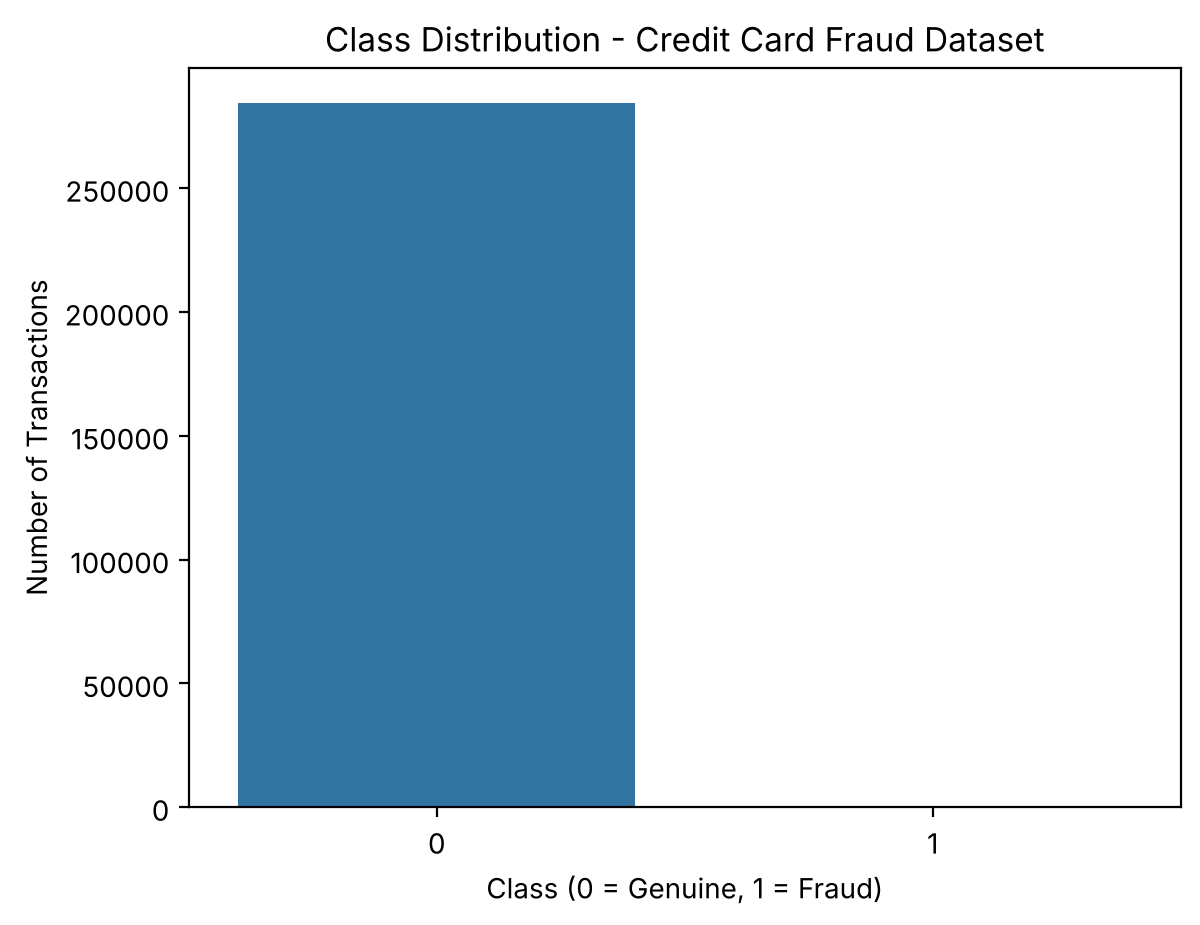

In [6]:
print(df1['Class'].value_counts())

print("\nPercentage Distribution:")
print(df1['Class'].value_counts(normalize=True) * 100)

sns.countplot(x='Class', data=df1)
plt.title("Class Distribution - Credit Card Fraud Dataset")
plt.xlabel("Class (0 = Genuine, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.show()

In [7]:
X1 = df1.drop(columns=["Class"])
y1 = df1["Class"]

print("Feature shape:", X1.shape)
print("Target shape:", y1.shape)

print("\nTarget distribution:")
print(y1.value_counts())

Feature shape: (284807, 30)
Target shape: (284807,)

Target distribution:
Class
0    284315
1       492
Name: count, dtype: int64


In [8]:
print("Feature Columns:")
print(X1.columns.tolist())

print("\nTarget Distribution:")
print(y1.value_counts())

Feature Columns:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']

Target Distribution:
Class
0    284315
1       492
Name: count, dtype: int64


In [9]:
X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1,
    y1,
    test_size=0.20,
    random_state=42,
    stratify=y1
)

print("Training Data:", X1_train.shape)
print("Testing Data:", X1_test.shape)

print("\nTraining Target Distribution:")
print(y1_train.value_counts())

print("\nTesting Target Distribution:")
print(y1_test.value_counts())

Training Data: (227845, 30)
Testing Data: (56962, 30)

Training Target Distribution:
Class
0    227451
1       394
Name: count, dtype: int64

Testing Target Distribution:
Class
0    56864
1       98
Name: count, dtype: int64


In [10]:
scaler1 = StandardScaler()

X1_train_scaled = scaler1.fit_transform(X1_train)
X1_test_scaled = scaler1.transform(X1_test)

print("Training and testing features standardized.")

Training and testing features standardized.


### Baseline Logistic Regression

In [11]:
baseline_model1 = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [12]:
baseline_model1.fit(X1_train_scaled, y1_train)

print("Baseline model trained successfully.")

Baseline model trained successfully.


In [13]:
baseline_pred1 = baseline_model1.predict(X1_test_scaled)

baseline_prob1 = baseline_model1.predict_proba(
    X1_test_scaled
)[:, 1]

print("Baseline predictions generated.")

Baseline predictions generated.


In [14]:
baseline_pr_auc1 = average_precision_score(
    y1_test,
    baseline_prob1
)

baseline_precision1 = precision_score(
    y1_test,
    baseline_pred1,
    zero_division=0
)

baseline_recall1 = recall_score(
    y1_test,
    baseline_pred1,
    zero_division=0
)

print("BASELINE MODEL RESULTS")
print("----------------------")
print("PR-AUC:", baseline_pr_auc1)
print("Precision:", baseline_precision1)
print("Recall:", baseline_recall1)

print("\nClassification Report:")
print(classification_report(
    y1_test,
    baseline_pred1,
    zero_division=0
))

BASELINE MODEL RESULTS
----------------------
PR-AUC: 0.7413820992780461
Precision: 0.8266666666666667
Recall: 0.6326530612244898

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.83      0.63      0.72        98

    accuracy                           1.00     56962
   macro avg       0.91      0.82      0.86     56962
weighted avg       1.00      1.00      1.00     56962



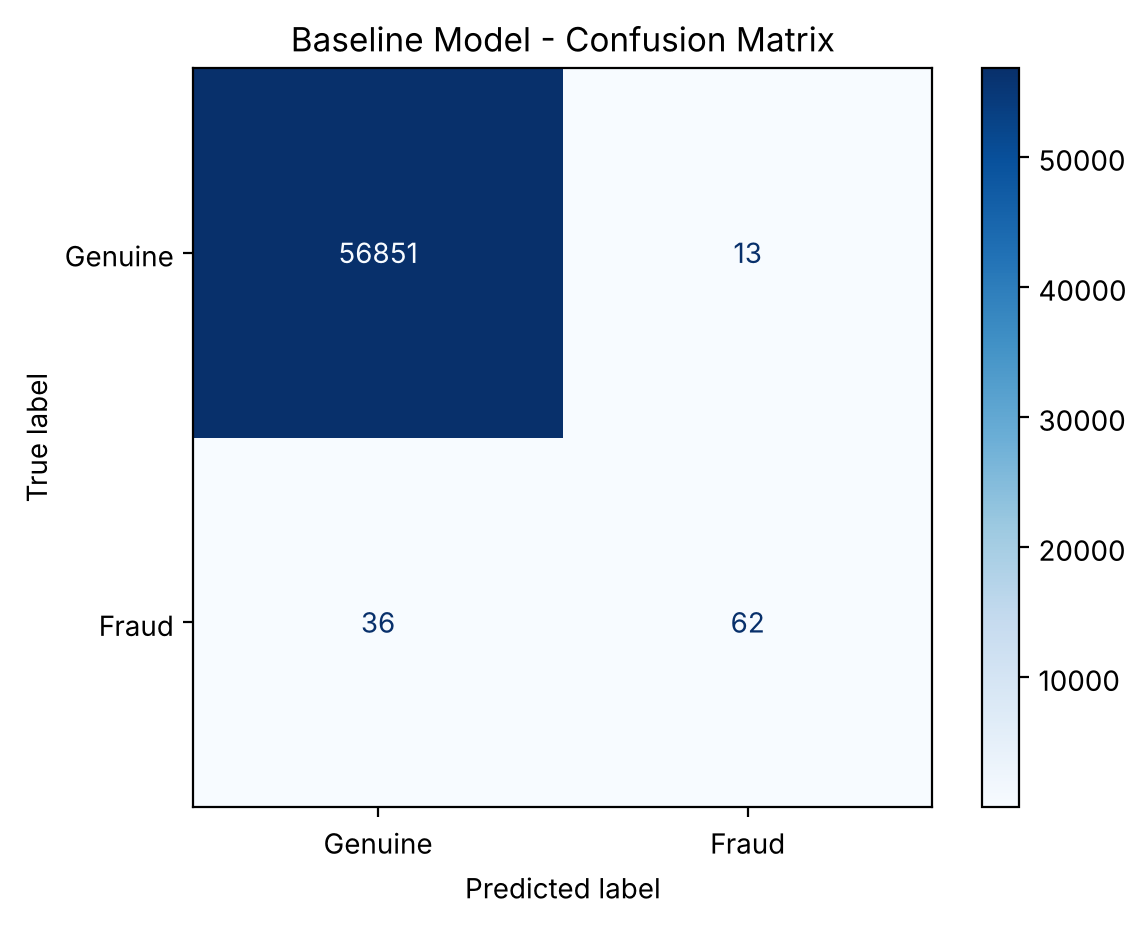

In [15]:
cm_baseline1 = confusion_matrix(
    y1_test,
    baseline_pred1
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_baseline1,
    display_labels=['Genuine', 'Fraud']
)

disp.plot(cmap='Blues')
plt.title("Baseline Model - Confusion Matrix")
plt.show()

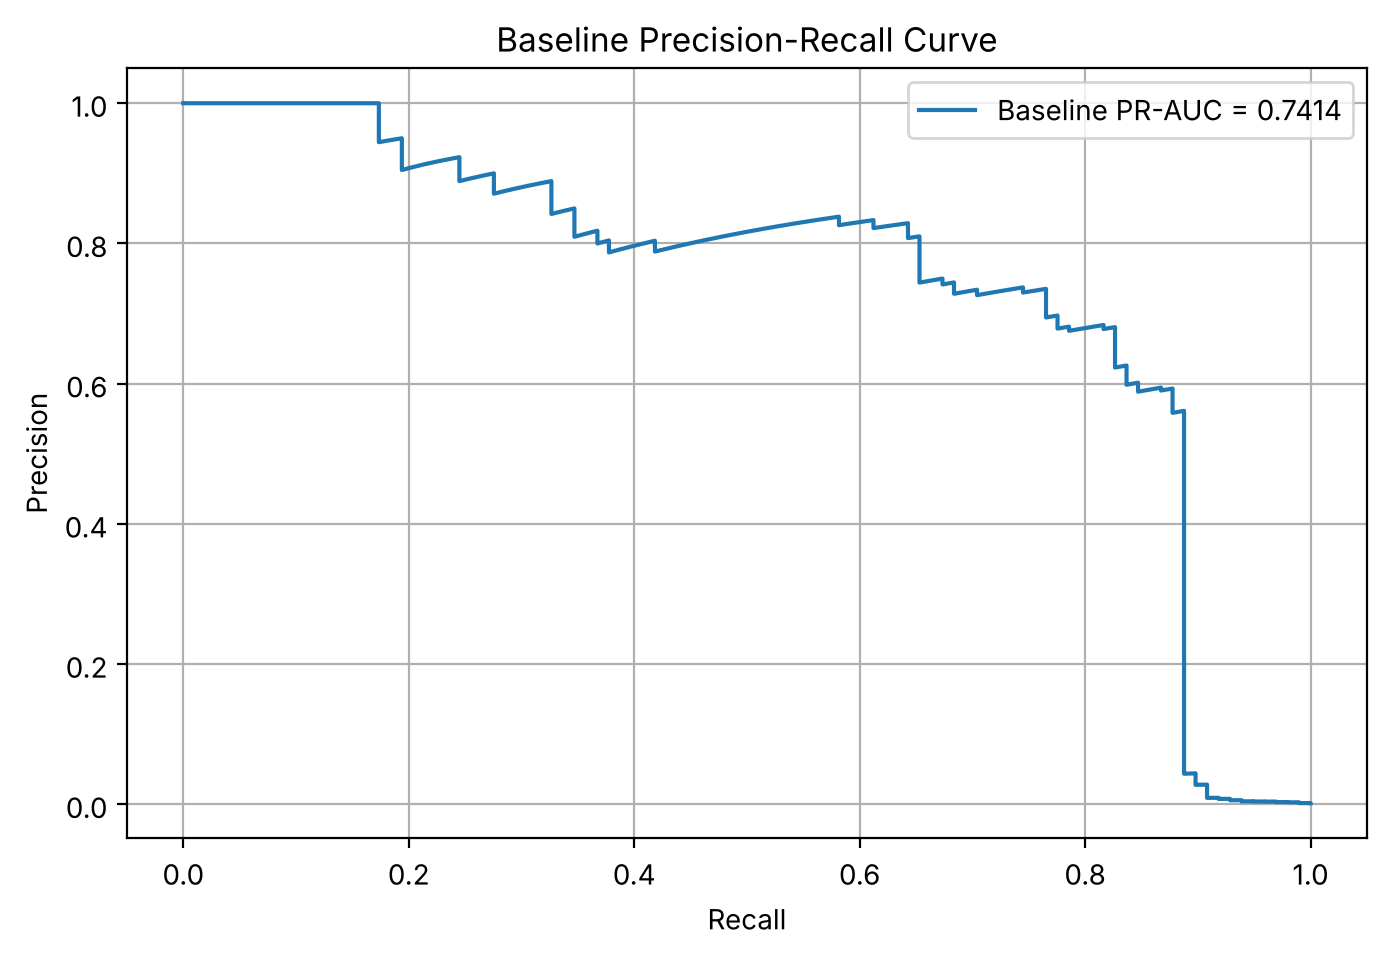

In [16]:
precision_values1, recall_values1, thresholds1 = (
    precision_recall_curve(y1_test, baseline_prob1)
)

plt.figure(figsize=(8, 5))

plt.plot(
    recall_values1,
    precision_values1,
    label=f'Baseline PR-AUC = {baseline_pr_auc1:.4f}'
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Baseline Precision-Recall Curve")
plt.legend()
plt.grid()
plt.show()

### SMOTE

In [17]:
smote1 = SMOTE(
    sampling_strategy=0.1,
    random_state=42,
    k_neighbors=5
)

In [18]:
X1_train_smote, y1_train_smote = smote1.fit_resample(
    X1_train_scaled,
    y1_train
)

print("Before SMOTE:")
print(y1_train.value_counts())

print("\nAfter SMOTE:")
print(pd.Series(y1_train_smote).value_counts())

Before SMOTE:
Class
0    227451
1       394
Name: count, dtype: int64

After SMOTE:
Class
0    227451
1     22745
Name: count, dtype: int64


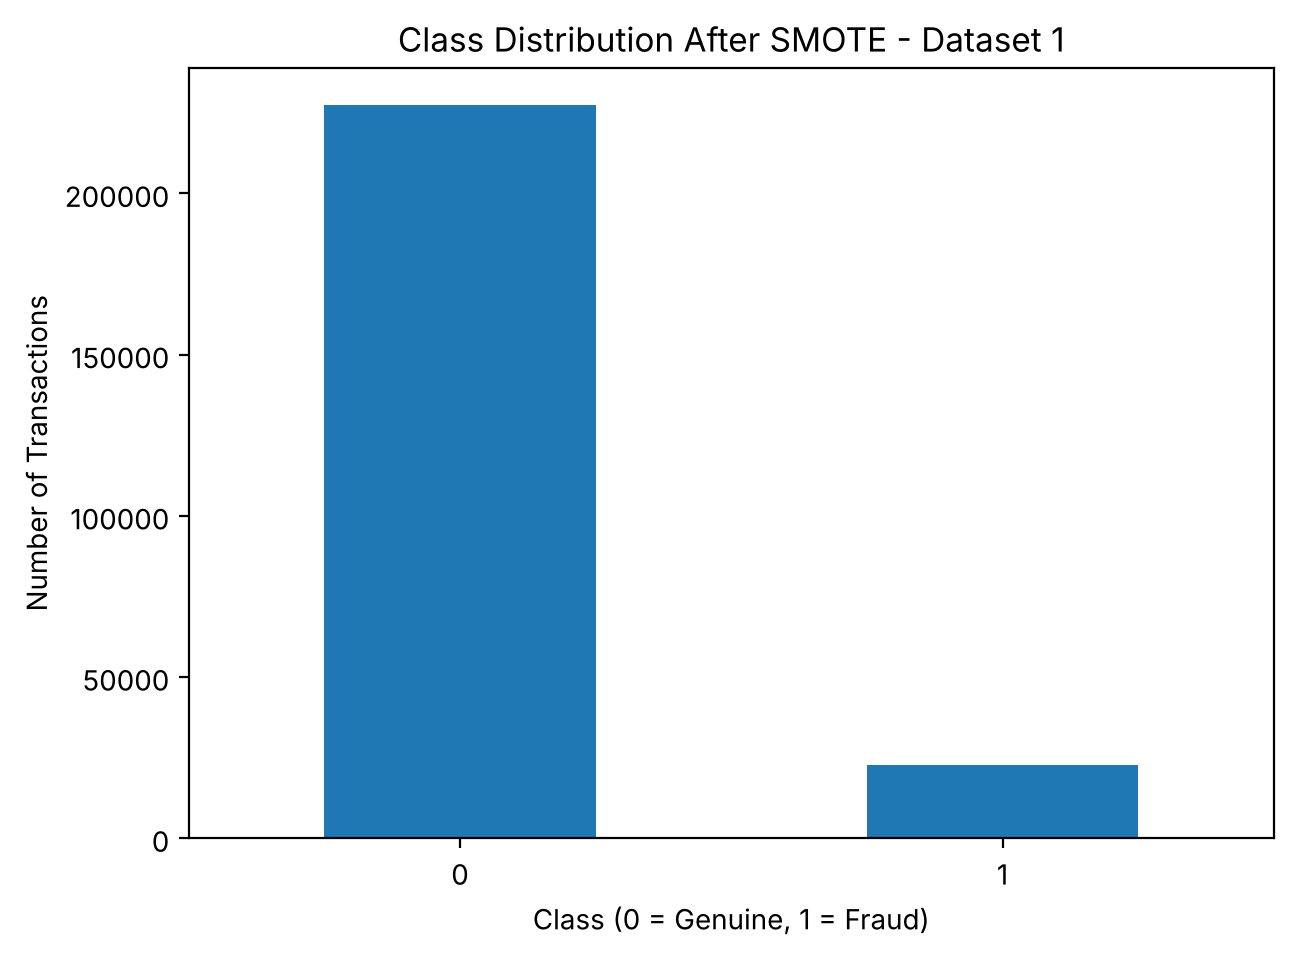

In [19]:
smote_distribution1 = pd.Series(y1_train_smote).value_counts()

smote_distribution1.plot(
    kind='bar',
    figsize=(7, 5)
)

plt.title("Class Distribution After SMOTE - Dataset 1")
plt.xlabel("Class (0 = Genuine, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.show()

In [20]:
smote_model1 = LogisticRegression(
    max_iter=1000,
    random_state=42
)

smote_model1.fit(
    X1_train_smote,
    y1_train_smote
)

print("SMOTE Logistic Regression model trained successfully.")

SMOTE Logistic Regression model trained successfully.


In [21]:
smote_pred1 = smote_model1.predict(X1_test_scaled)

smote_prob1 = smote_model1.predict_proba(
    X1_test_scaled
)[:, 1]

print("SMOTE predictions generated.")

SMOTE predictions generated.


In [22]:
smote_pr_auc1 = average_precision_score(
    y1_test,
    smote_prob1
)

smote_precision1 = precision_score(
    y1_test,
    smote_pred1,
    zero_division=0
)

smote_recall1 = recall_score(
    y1_test,
    smote_pred1,
    zero_division=0
)

print("SMOTE MODEL RESULTS")
print("-------------------")
print("PR-AUC:", smote_pr_auc1)
print("Precision:", smote_precision1)
print("Recall:", smote_recall1)

print("\nClassification Report:")
print(classification_report(
    y1_test,
    smote_pred1,
    zero_division=0
))

SMOTE MODEL RESULTS
-------------------
PR-AUC: 0.7504885994955915
Precision: 0.3522267206477733
Recall: 0.8877551020408163

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.35      0.89      0.50        98

    accuracy                           1.00     56962
   macro avg       0.68      0.94      0.75     56962
weighted avg       1.00      1.00      1.00     56962



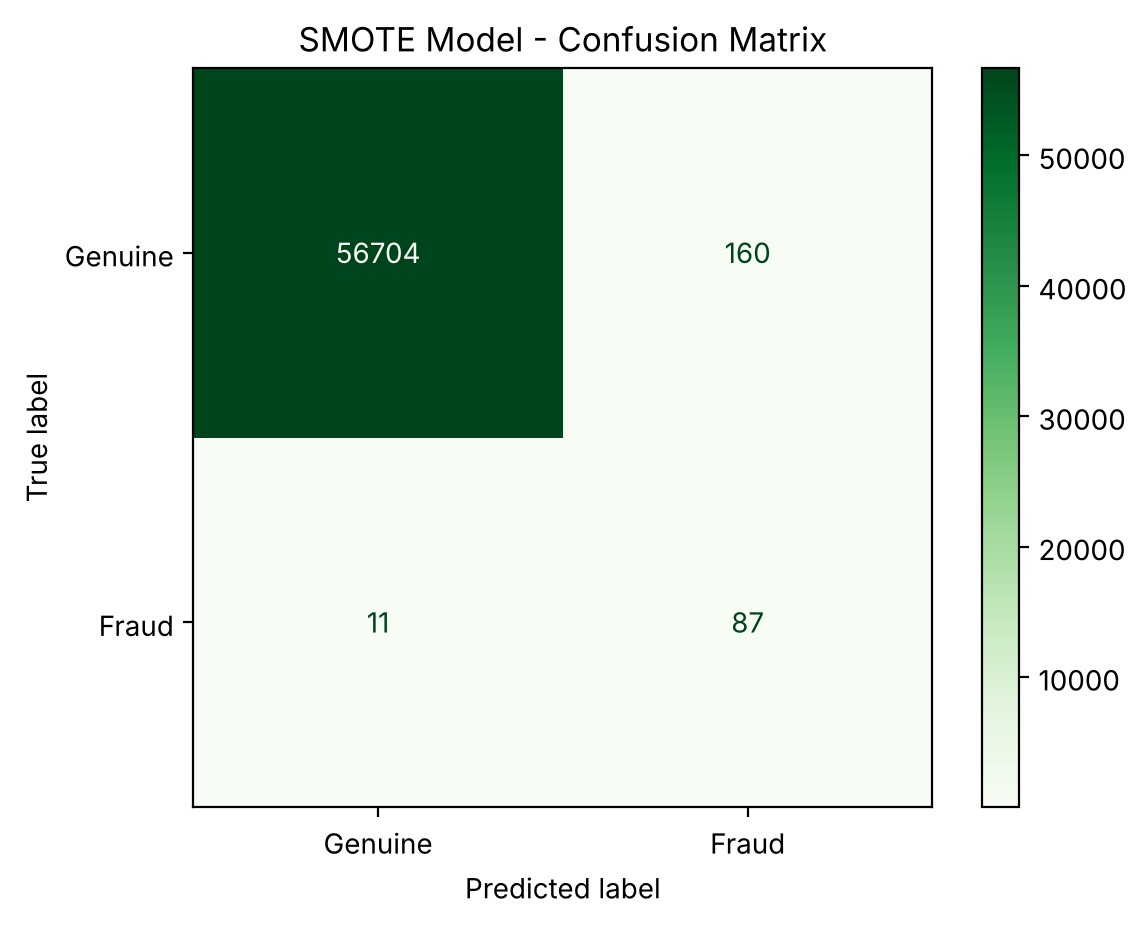

In [23]:
cm_smote1 = confusion_matrix(
    y1_test,
    smote_pred1
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_smote1,
    display_labels=['Genuine', 'Fraud']
)

disp.plot(cmap='Greens')
plt.title("SMOTE Model - Confusion Matrix")
plt.show()

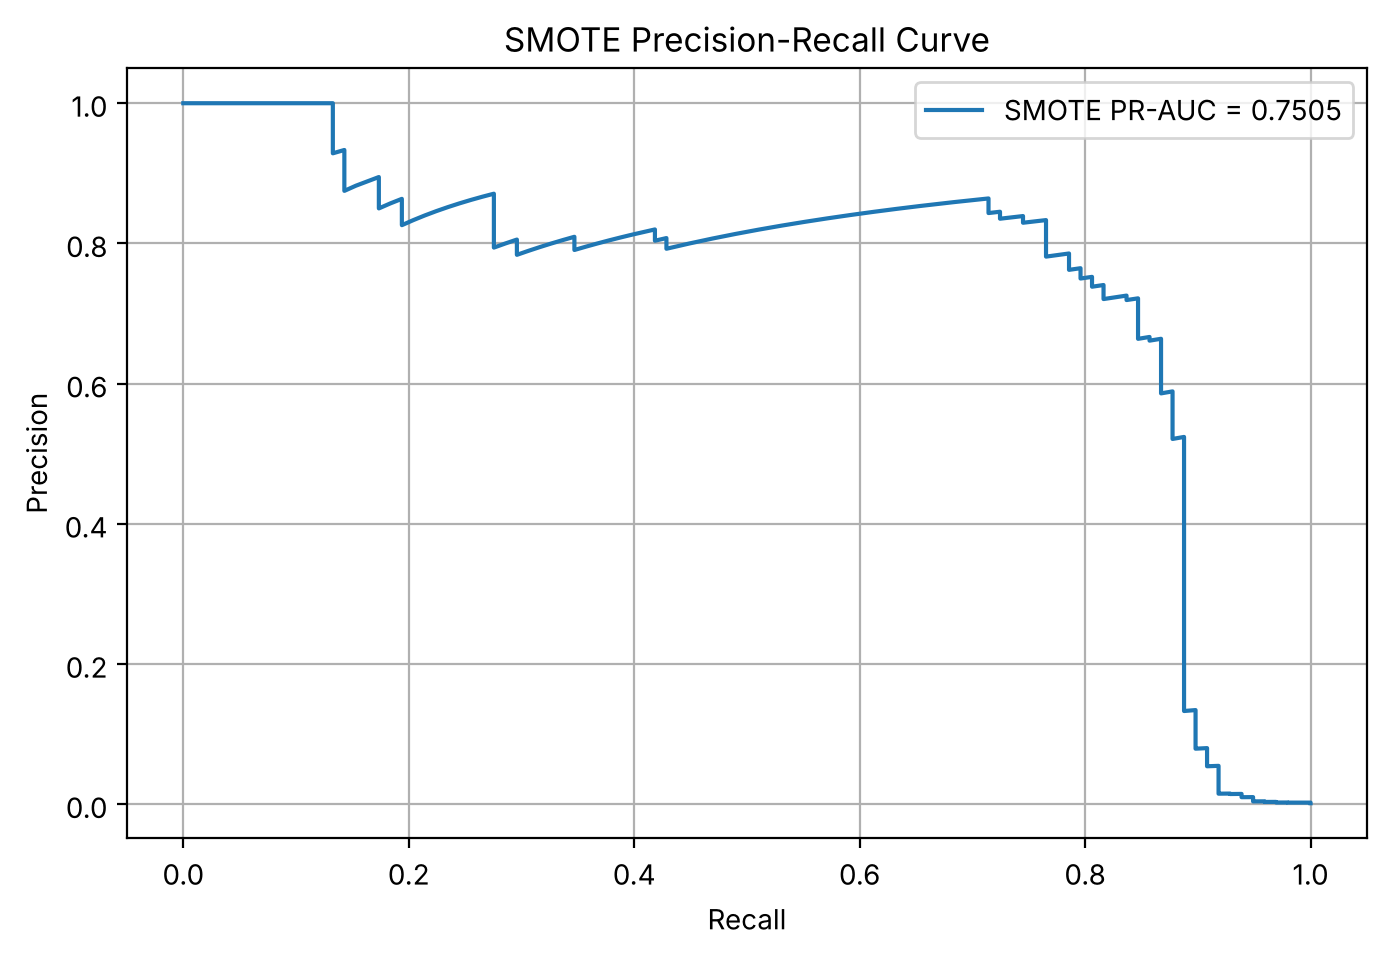

In [24]:
precision_values_smote1, recall_values_smote1, thresholds_smote1 = (
    precision_recall_curve(y1_test, smote_prob1)
)

plt.figure(figsize=(8, 5))

plt.plot(
    recall_values_smote1,
    precision_values_smote1,
    label=f'SMOTE PR-AUC = {smote_pr_auc1:.4f}'
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("SMOTE Precision-Recall Curve")
plt.legend()
plt.grid()
plt.show()

### Economic Cost

In [25]:
FN_COST = 5000
FP_COST = 100

def calculate_cost(y_true, y_pred):

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred
    ).ravel()

    total_cost = (fn * FN_COST) + (fp * FP_COST)

    return total_cost, fp, fn

In [26]:
baseline_cost1, baseline_fp1, baseline_fn1 = calculate_cost(
    y1_test,
    baseline_pred1
)

smote_cost1, smote_fp1, smote_fn1 = calculate_cost(
    y1_test,
    smote_pred1
)

print("BASELINE ECONOMIC COST")
print("----------------------")
print("False Positives:", baseline_fp1)
print("False Negatives:", baseline_fn1)
print("Total Cost: ₹", baseline_cost1)

print("\nSMOTE ECONOMIC COST")
print("-------------------")
print("False Positives:", smote_fp1)
print("False Negatives:", smote_fn1)
print("Total Cost: ₹", smote_cost1)

BASELINE ECONOMIC COST
----------------------
False Positives: 13
False Negatives: 36
Total Cost: ₹ 181300

SMOTE ECONOMIC COST
-------------------
False Positives: 160
False Negatives: 11
Total Cost: ₹ 71000


In [27]:
results1 = pd.DataFrame({
    'Model': ['Baseline Logistic Regression', 'Logistic Regression + SMOTE'],
    'PR-AUC': [baseline_pr_auc1, smote_pr_auc1],
    'Precision': [baseline_precision1, smote_precision1],
    'Recall': [baseline_recall1, smote_recall1],
    'False Positives': [baseline_fp1, smote_fp1],
    'False Negatives': [baseline_fn1, smote_fn1],
    'Economic Cost (₹)': [baseline_cost1, smote_cost1]
})

results1

,Model,PR-AUC,Precision,Recall,False Positives,False Negatives,Economic Cost (₹)
0,Baseline Logistic Regression,0.741382,0.826667,0.632653,13,36,181300
1,Logistic Regression + SMOTE,0.750489,0.352227,0.887755,160,11,71000


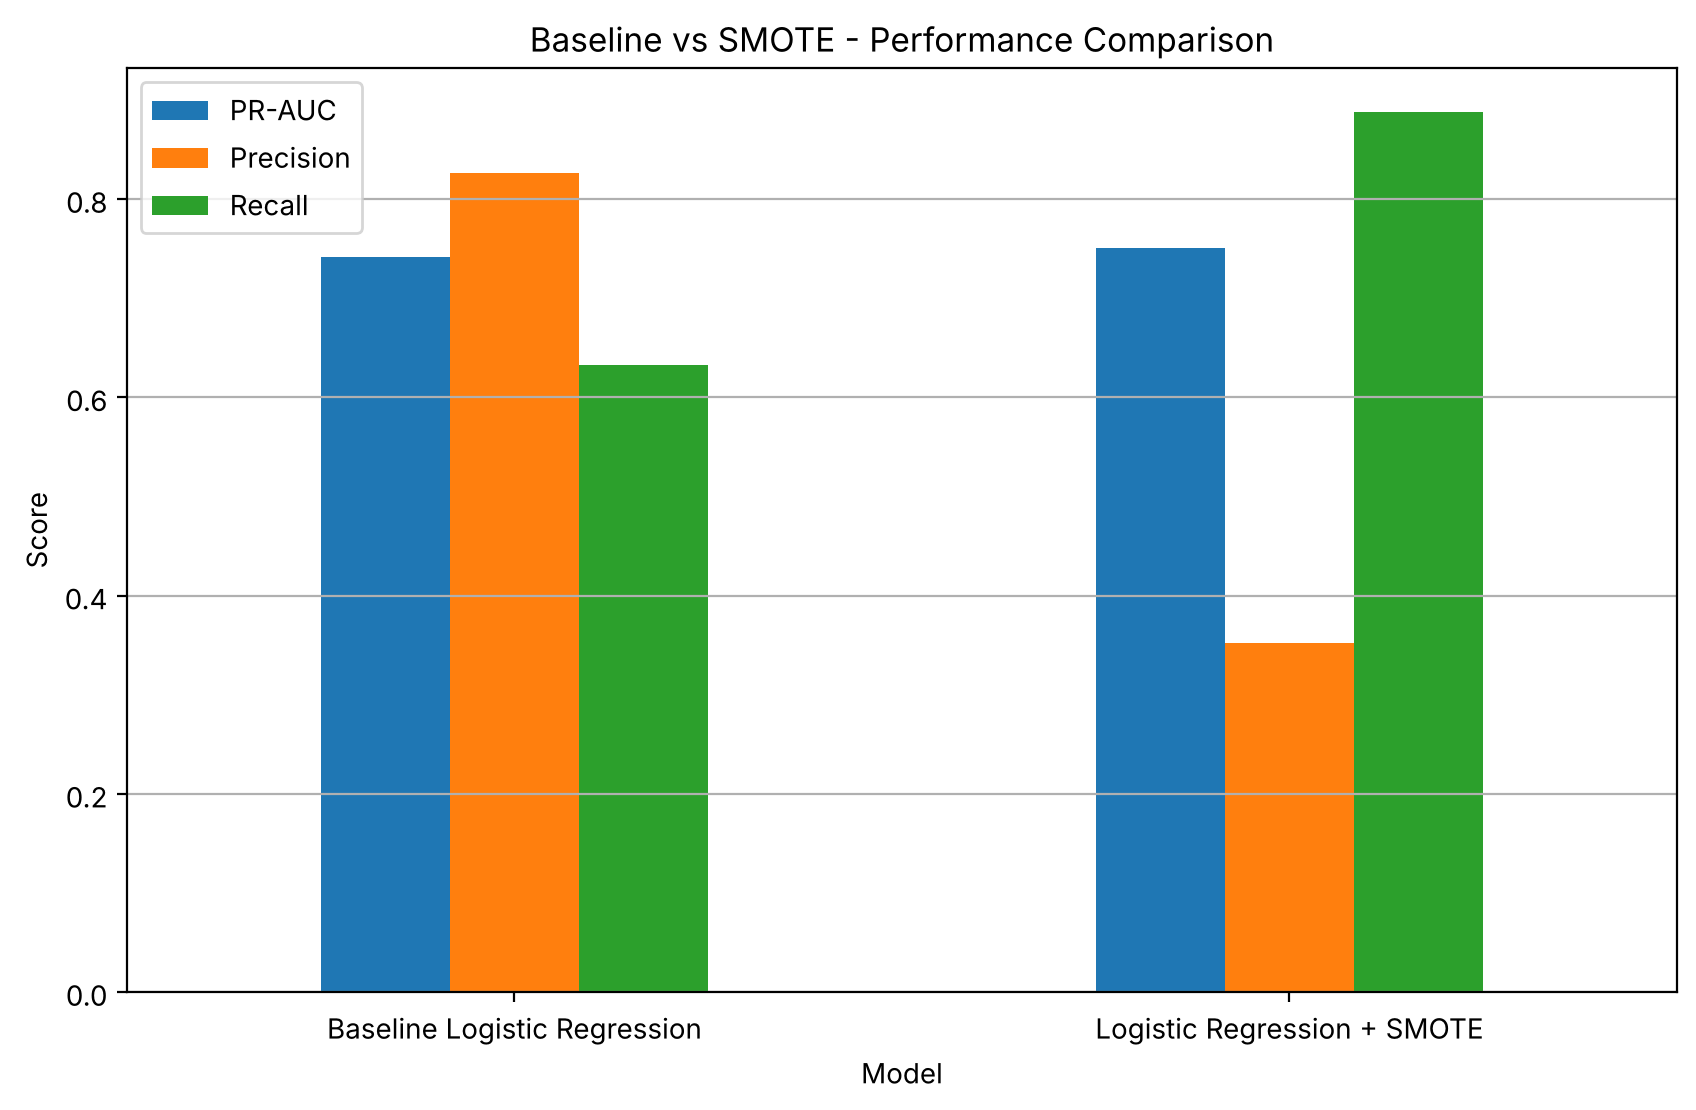

In [28]:
metrics1 = ['PR-AUC', 'Precision', 'Recall']

comparison1 = results1.set_index('Model')[metrics1]

comparison1.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title("Baseline vs SMOTE - Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis='y')
plt.show()

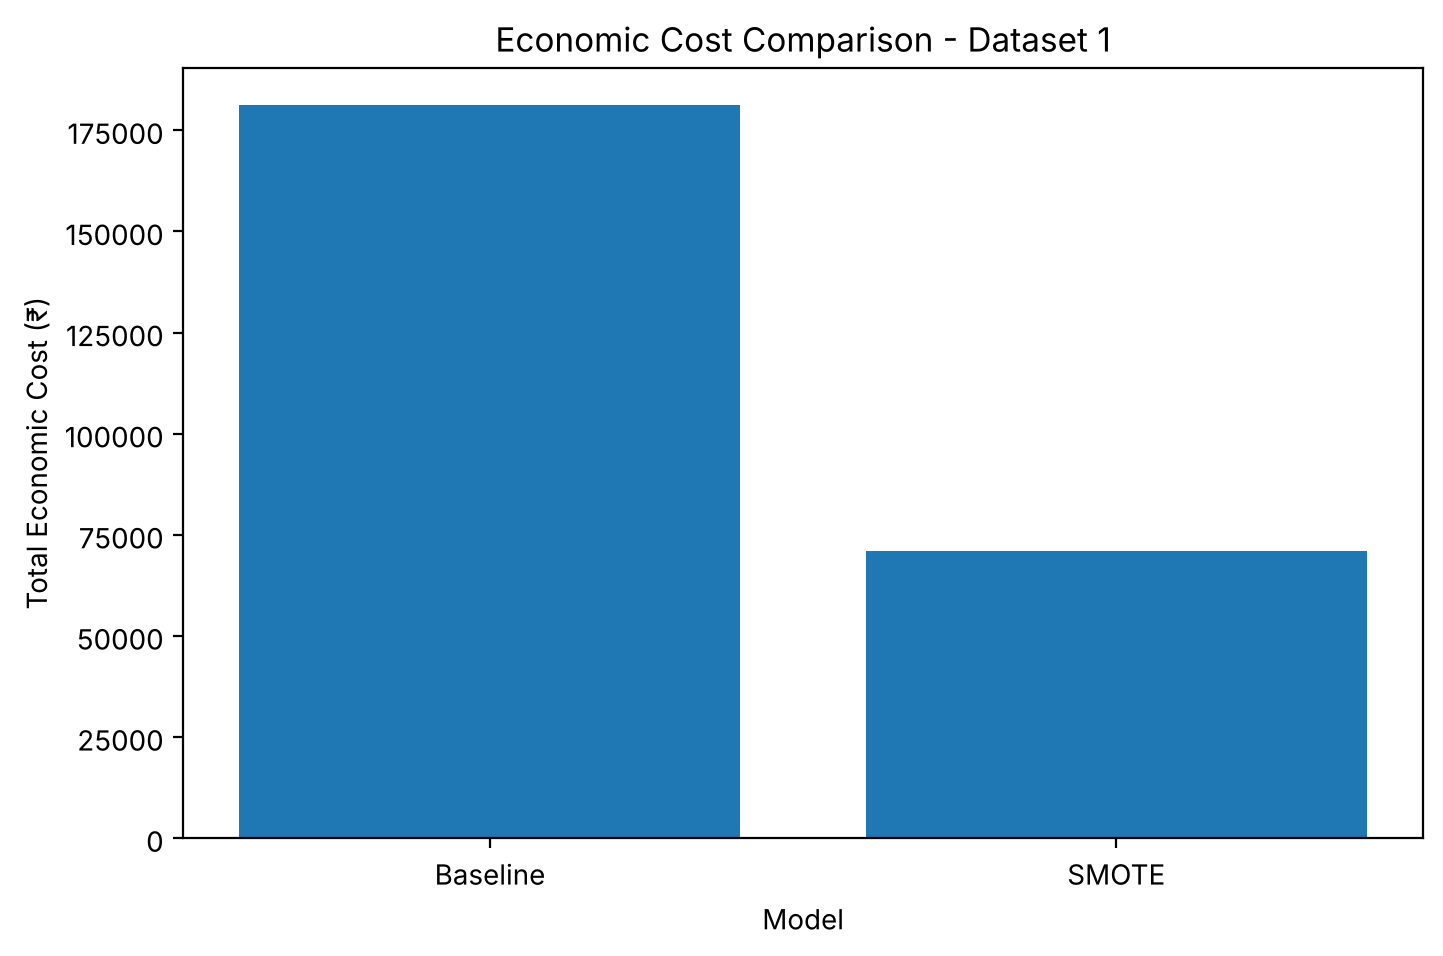

In [29]:
plt.figure(figsize=(8, 5))

plt.bar(
    ['Baseline', 'SMOTE'],
    [baseline_cost1, smote_cost1]
)

plt.title("Economic Cost Comparison - Dataset 1")
plt.ylabel("Total Economic Cost (₹)")
plt.xlabel("Model")
plt.show()

In [30]:
if baseline_pr_auc1 != 0:
    pr_auc_change1 = (
        (smote_pr_auc1 - baseline_pr_auc1)
        / baseline_pr_auc1
    ) * 100
else:
    pr_auc_change1 = 0

if baseline_cost1 != 0:
    cost_change1 = (
        (baseline_cost1 - smote_cost1)
        / baseline_cost1
    ) * 100
else:
    cost_change1 = 0

print("Percentage Change in PR-AUC:", round(pr_auc_change1, 2), "%")
print("Percentage Reduction in Economic Cost:", round(cost_change1, 2), "%")

Percentage Change in PR-AUC: 1.23 %
Percentage Reduction in Economic Cost: 60.84 %


In [31]:
results1.to_csv(
    'Credit_Card_Fraud_Results.csv',
    index=False
)

print("Results saved successfully.")

Results saved successfully.


## 2. PaySim Dataset

In [32]:
df2 = pd.read_csv(
    "/content/PS_20174392719_1491204439457_log.csv"
)

print("Dataset shape:", df2.shape)
display(df2.head())

print("\nFraud distribution:")
print(df2["isFraud"].value_counts())

Dataset shape: (6362620, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0



Fraud distribution:
isFraud
0    6354407
1       8213
Name: count, dtype: int64


In [33]:
print("Missing Values:")
print(df2.isnull().sum())

print("\nTotal Missing Values:")
print(df2.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df2.duplicated().sum())

Missing Values:


step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

Total Missing Values:


0

Duplicate Rows:


0


Transaction Distribution:
isFraud
0    6354407
1       8213
Name: count, dtype: int64

Percentage Distribution:
isFraud
0    99.8709
1     0.1291
Name: proportion, dtype: float64


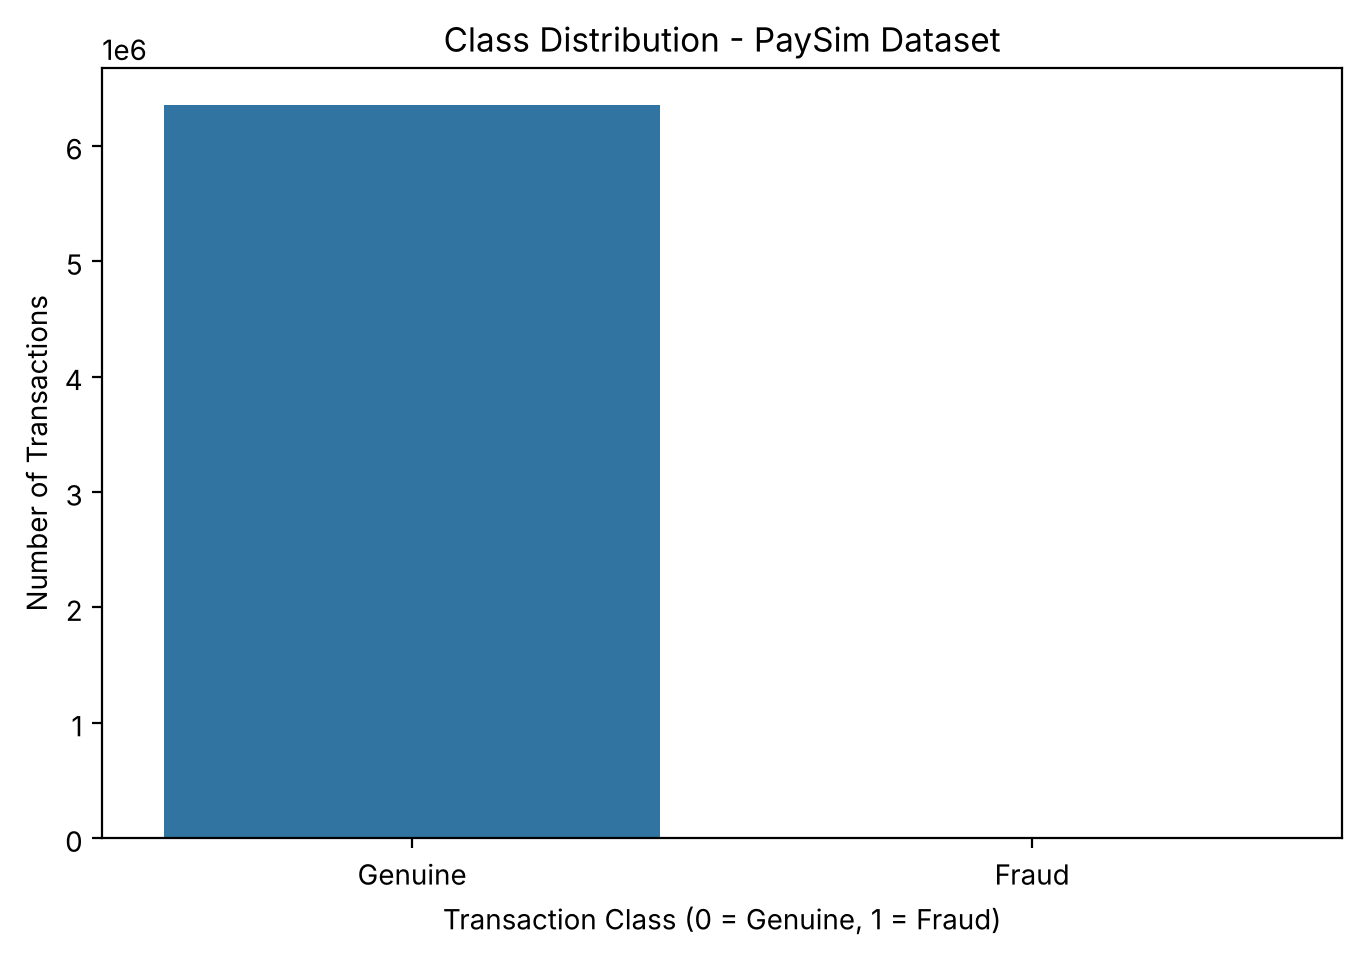

In [34]:
class_counts = df2["isFraud"].value_counts().sort_index()

print("Transaction Distribution:")
print(class_counts)

print("\nPercentage Distribution:")
print(
    (df2["isFraud"].value_counts(normalize=True) * 100).round(4)
)

plt.figure(figsize=(8, 5))

sns.countplot(data=df2, x="isFraud")

plt.title("Class Distribution - PaySim Dataset")
plt.xlabel("Transaction Class (0 = Genuine, 1 = Fraud)")
plt.ylabel("Number of Transactions")

plt.xticks([0, 1], ["Genuine", "Fraud"])
plt.show()

In [35]:
df2_sample = (
    df2.groupby("isFraud", group_keys=False)
       .sample(
           frac=0.10,
           random_state=42
       )
       .reset_index(drop=True)
)

print("Original Dataset Shape:", df2.shape)
print("Sampled Dataset Shape:", df2_sample.shape)

print("\nSampled Class Distribution:")
print(df2_sample["isFraud"].value_counts())

Original Dataset Shape: (6362620, 11)
Sampled Dataset Shape: (636262, 11)

Sampled Class Distribution:
isFraud
0    635441
1       821
Name: count, dtype: int64


In [36]:
X2 = df2_sample.drop(
    columns=[
        "isFraud",
        "isFlaggedFraud",
        "nameOrig",
        "nameDest",
        "newbalanceOrig",
        "newbalanceDest"
    ],
    errors="ignore"
)

y2 = df2_sample["isFraud"]

print("Feature Shape:", X2.shape)
print("Target Shape:", y2.shape)

print("\nSelected Features:")
print(X2.columns.tolist())

Feature Shape: (636262, 5)
Target Shape: (636262,)

Selected Features:
['step', 'type', 'amount', 'oldbalanceOrg', 'oldbalanceDest']


In [37]:
numerical_features = [
    "step",
    "amount",
    "oldbalanceOrg",
    "oldbalanceDest"
]

categorical_features = [
    "type"
]

print("Numerical Features:", numerical_features)
print("Categorical Features:", categorical_features)

Numerical Features: ['step', 'amount', 'oldbalanceOrg', 'oldbalanceDest']
Categorical Features: ['type']


In [38]:
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2,
    y2,
    test_size=0.20,
    random_state=42,
    stratify=y2
)

print("Training Samples:", len(X2_train))
print("Testing Samples:", len(X2_test))

print("\nTraining Class Distribution:")
print(y2_train.value_counts())

print("\nTesting Class Distribution:")
print(y2_test.value_counts())

Training Samples: 509009
Testing Samples: 127253

Training Class Distribution:
isFraud
0    508352
1       657
Name: count, dtype: int64

Testing Class Distribution:
isFraud
0    127089
1       164
Name: count, dtype: int64


### SMOTENC

In [39]:

# Step 1: Encode numerical and categorical features separately

preprocessor_smote = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OrdinalEncoder(
                handle_unknown="use_encoded_value",
                unknown_value=-1
            ),
            categorical_features
        )
    ]
)

# Step 2: Apply SMOTENC to the training data
# Numerical columns: 0, 1, 2, 3
# Categorical column: 4

smotenc_pipeline = Pipeline([
    ("preprocessor", preprocessor_smote),

    ("smote", SMOTENC(
        categorical_features=[4],
        sampling_strategy=0.1,
        random_state=42,
        k_neighbors=5
    )),

    # Convert categorical feature back to one-hot representation
    ("onehot", ColumnTransformer(
        transformers=[
            ("num", "passthrough", [0, 1, 2, 3]),
            ("cat", OneHotEncoder(
                handle_unknown="ignore"
            ), [4])
        ]
    )),

    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Step 3: Train
smotenc_pipeline.fit(X2_train, y2_train)

# Step 4: Predict
y2_smotenc_pred = smotenc_pipeline.predict(X2_test)

y2_smotenc_scores = smotenc_pipeline.predict_proba(
    X2_test
)[:, 1]

print("SMOTENC model trained successfully!")
print("PR-AUC:", average_precision_score(y2_test, y2_smotenc_scores))
print("Precision:", precision_score(y2_test, y2_smotenc_pred, zero_division=0))
print("Recall:", recall_score(y2_test, y2_smotenc_pred, zero_division=0))
print(confusion_matrix(y2_test, y2_smotenc_pred))


SMOTENC model trained successfully!
PR-AUC: 0.4147678632639162
Precision: 0.13661971830985917
Recall: 0.5914634146341463
[[126476    613]
 [    67     97]]


### Baseline Logistic Regression

In [40]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [41]:
baseline_model2 = Pipeline([
    ("preprocessor", preprocessor),

    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

baseline_model2.fit(X2_train, y2_train)

print("Baseline Model Trained Successfully!")

Baseline Model Trained Successfully!


In [42]:
y2_baseline_pred = baseline_model2.predict(X2_test)

y2_baseline_scores = baseline_model2.predict_proba(
    X2_test
)[:, 1]

print("Baseline Predictions Completed!")

Baseline Predictions Completed!


In [43]:
baseline_pr_auc2 = average_precision_score(
    y2_test,
    y2_baseline_scores
)

baseline_precision2 = precision_score(
    y2_test,
    y2_baseline_pred,
    zero_division=0
)

baseline_recall2 = recall_score(
    y2_test,
    y2_baseline_pred,
    zero_division=0
)

print("BASELINE RESULTS - DATASET 2")
print("--------------------------------")

print(f"PR-AUC: {baseline_pr_auc2:.4f}")
print(f"Precision: {baseline_precision2:.4f}")
print(f"Recall: {baseline_recall2:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y2_test,
        y2_baseline_pred,
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y2_test, y2_baseline_pred))

BASELINE RESULTS - DATASET 2
--------------------------------
PR-AUC: 0.2093
Precision: 1.0000
Recall: 0.0793

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    127089
           1       1.00      0.08      0.15       164

    accuracy                           1.00    127253
   macro avg       1.00      0.54      0.57    127253
weighted avg       1.00      1.00      1.00    127253


Confusion Matrix:
[[127089      0]
 [   151     13]]


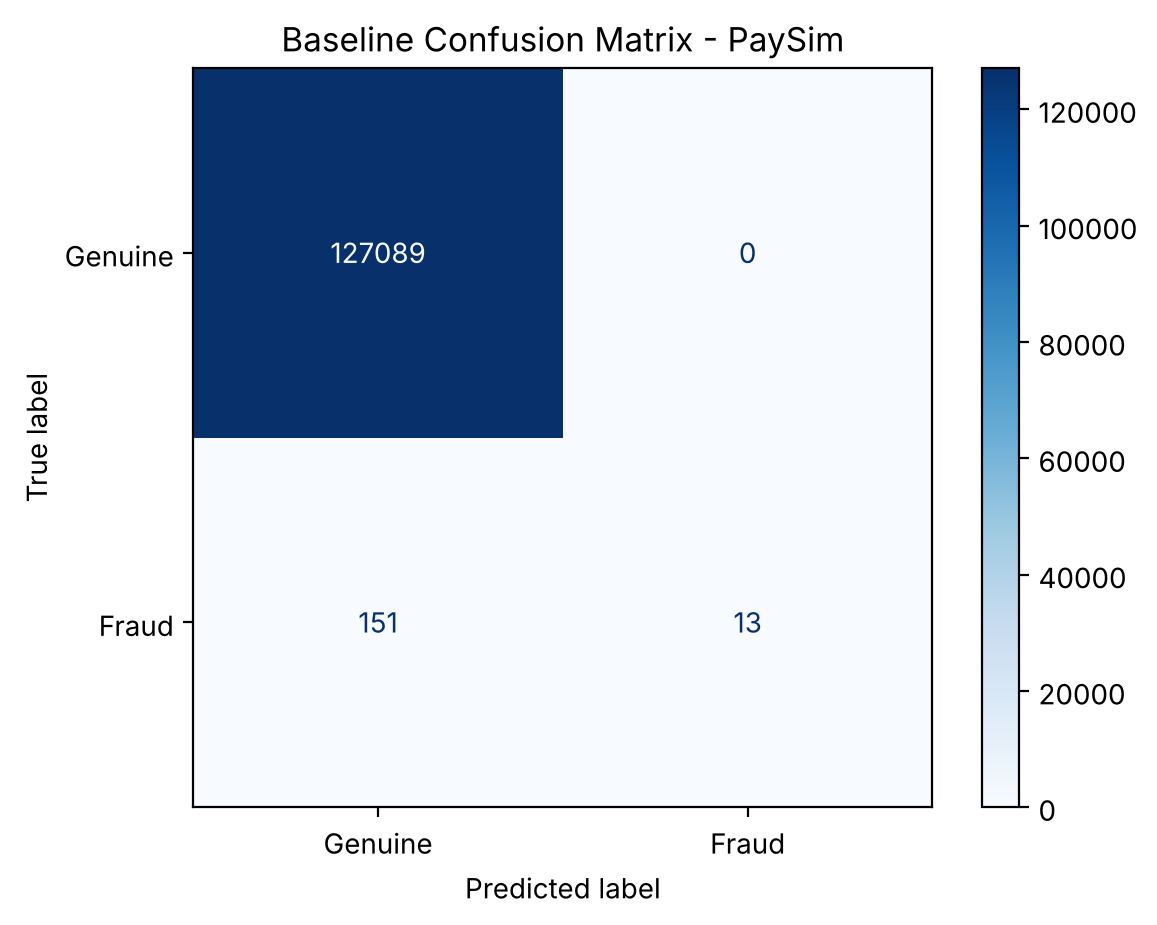

In [44]:
ConfusionMatrixDisplay.from_predictions(
    y2_test,
    y2_baseline_pred,
    display_labels=["Genuine", "Fraud"],
    cmap="Blues"
)

plt.title("Baseline Confusion Matrix - PaySim")
plt.show()

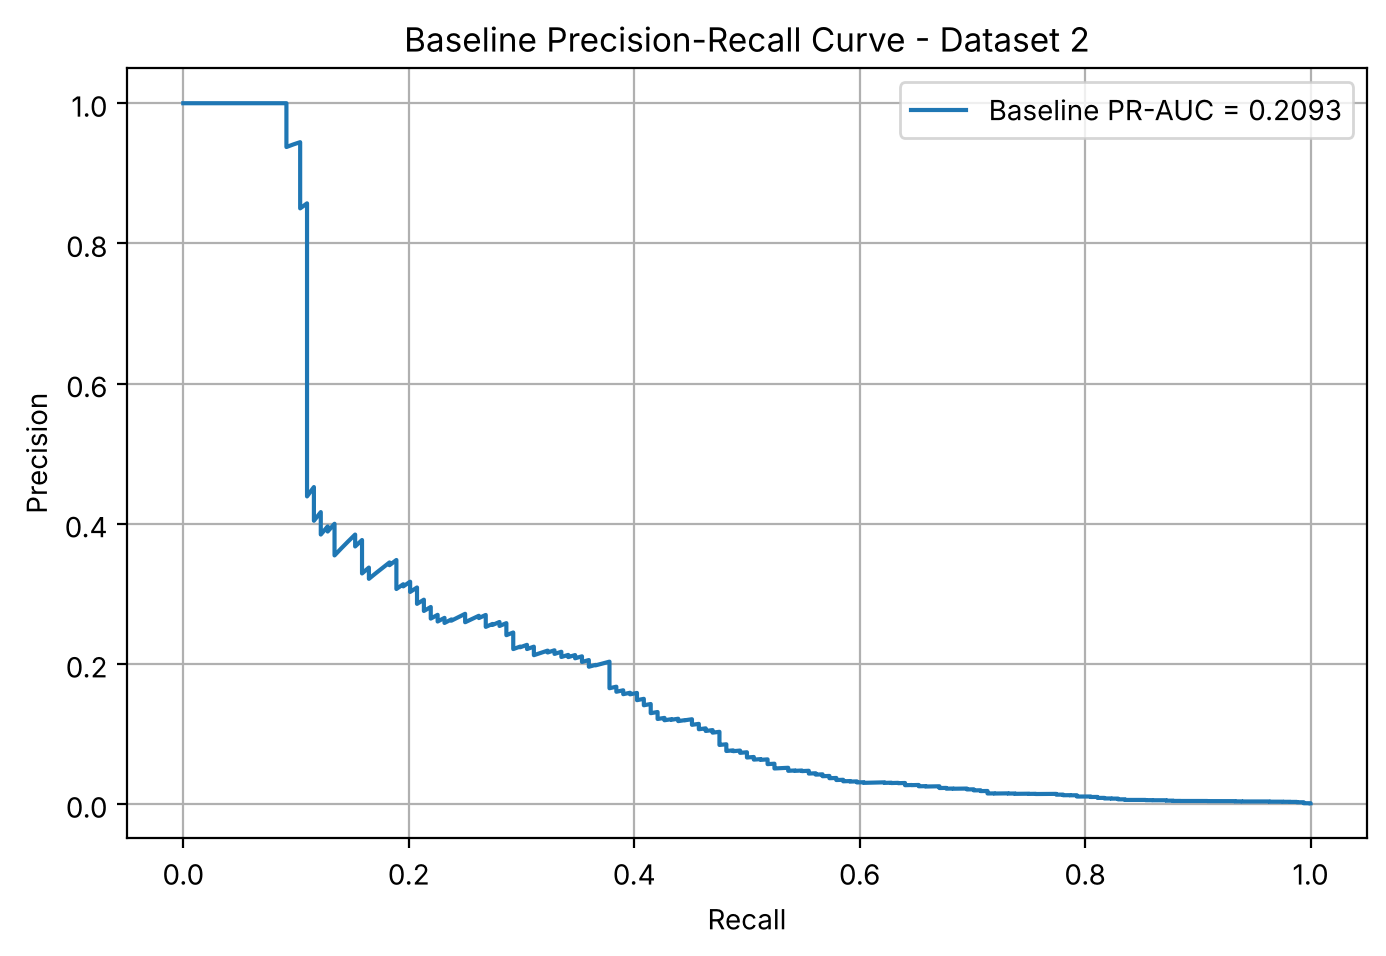

In [45]:
precision_values2, recall_values2, thresholds2 = (
    precision_recall_curve(
        y2_test,
        y2_baseline_scores
    )
)

plt.figure(figsize=(8, 5))

plt.plot(
    recall_values2,
    precision_values2,
    label=f"Baseline PR-AUC = {baseline_pr_auc2:.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Baseline Precision-Recall Curve - Dataset 2")

plt.legend()
plt.grid(True)

plt.show()

### SMOTE

In [46]:
smote_model2 = Pipeline([
    ("preprocessor", preprocessor),

    ("smote", SMOTE(
        sampling_strategy=0.1,
        random_state=42,
        k_neighbors=5
    )),

    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

smote_model2.fit(X2_train, y2_train)

print("SMOTE Model Trained Successfully!")

SMOTE Model Trained Successfully!


In [47]:
X2_train_processed = preprocessor.fit_transform(X2_train)

X2_resampled, y2_resampled = SMOTE(
    sampling_strategy=0.1,
    random_state=42,
    k_neighbors=5
).fit_resample(
    X2_train_processed,
    y2_train
)

print("Original Training Distribution:")
print(y2_train.value_counts())

print("\nResampled Training Distribution:")
print(pd.Series(y2_resampled).value_counts())

Original Training Distribution:
isFraud
0    508352
1       657
Name: count, dtype: int64

Resampled Training Distribution:
isFraud
0    508352
1     50835
Name: count, dtype: int64


In [48]:
y2_smote_pred = smote_model2.predict(X2_test)

y2_smote_scores = smote_model2.predict_proba(
    X2_test
)[:, 1]

print("SMOTE Predictions Completed!")

SMOTE Predictions Completed!


In [49]:
smote_pr_auc2 = average_precision_score(
    y2_test,
    y2_smote_scores
)

smote_precision2 = precision_score(
    y2_test,
    y2_smote_pred,
    zero_division=0
)

smote_recall2 = recall_score(
    y2_test,
    y2_smote_pred,
    zero_division=0
)

print("SMOTE RESULTS - DATASET 2")
print("--------------------------------")

print(f"PR-AUC: {smote_pr_auc2:.4f}")
print(f"Precision: {smote_precision2:.4f}")
print(f"Recall: {smote_recall2:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y2_test,
        y2_smote_pred,
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y2_test, y2_smote_pred))

SMOTE RESULTS - DATASET 2
--------------------------------
PR-AUC: 0.4152
Precision: 0.1372
Recall: 0.5915

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    127089
           1       0.14      0.59      0.22       164

    accuracy                           0.99    127253
   macro avg       0.57      0.79      0.61    127253
weighted avg       1.00      0.99      1.00    127253


Confusion Matrix:
[[126479    610]
 [    67     97]]


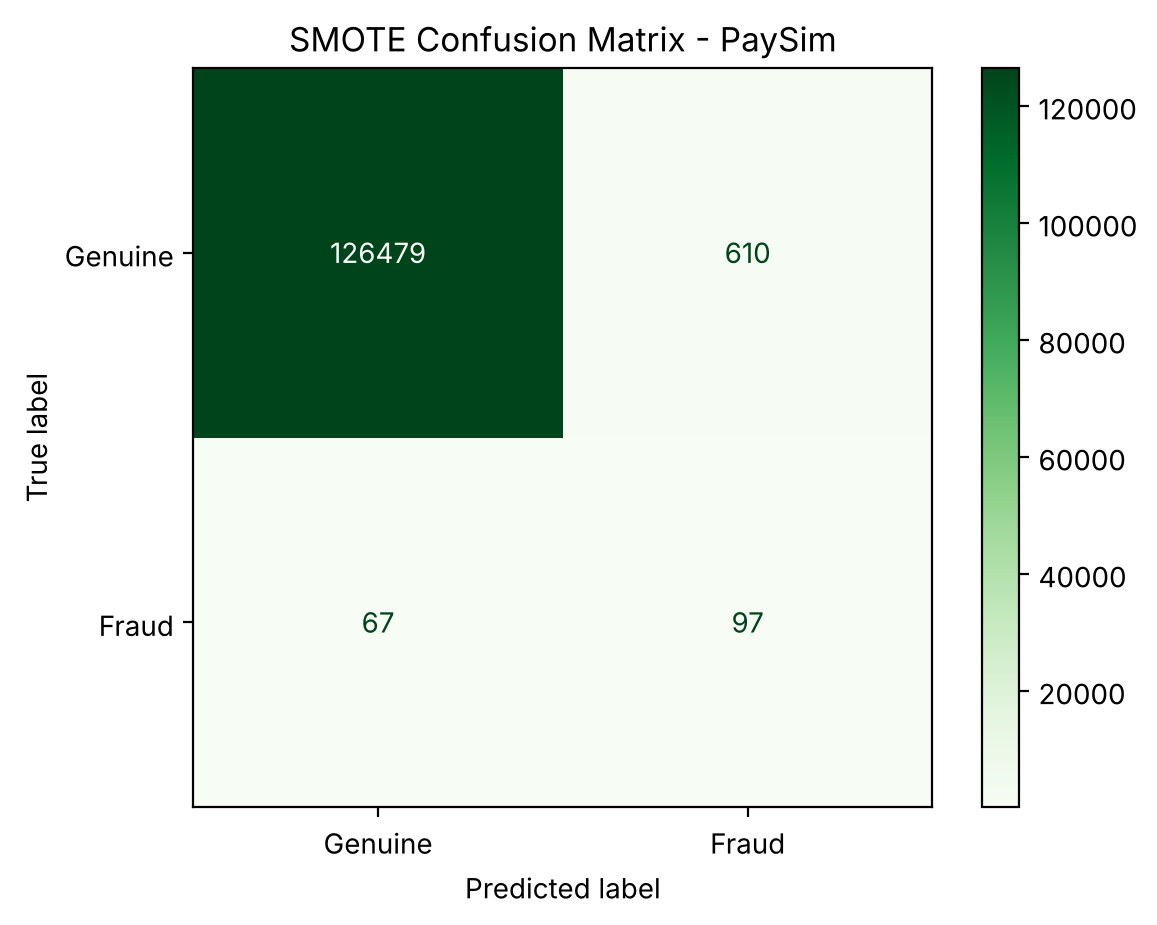

In [50]:
ConfusionMatrixDisplay.from_predictions(
    y2_test,
    y2_smote_pred,
    display_labels=["Genuine", "Fraud"],
    cmap="Greens"
)

plt.title("SMOTE Confusion Matrix - PaySim")
plt.show()

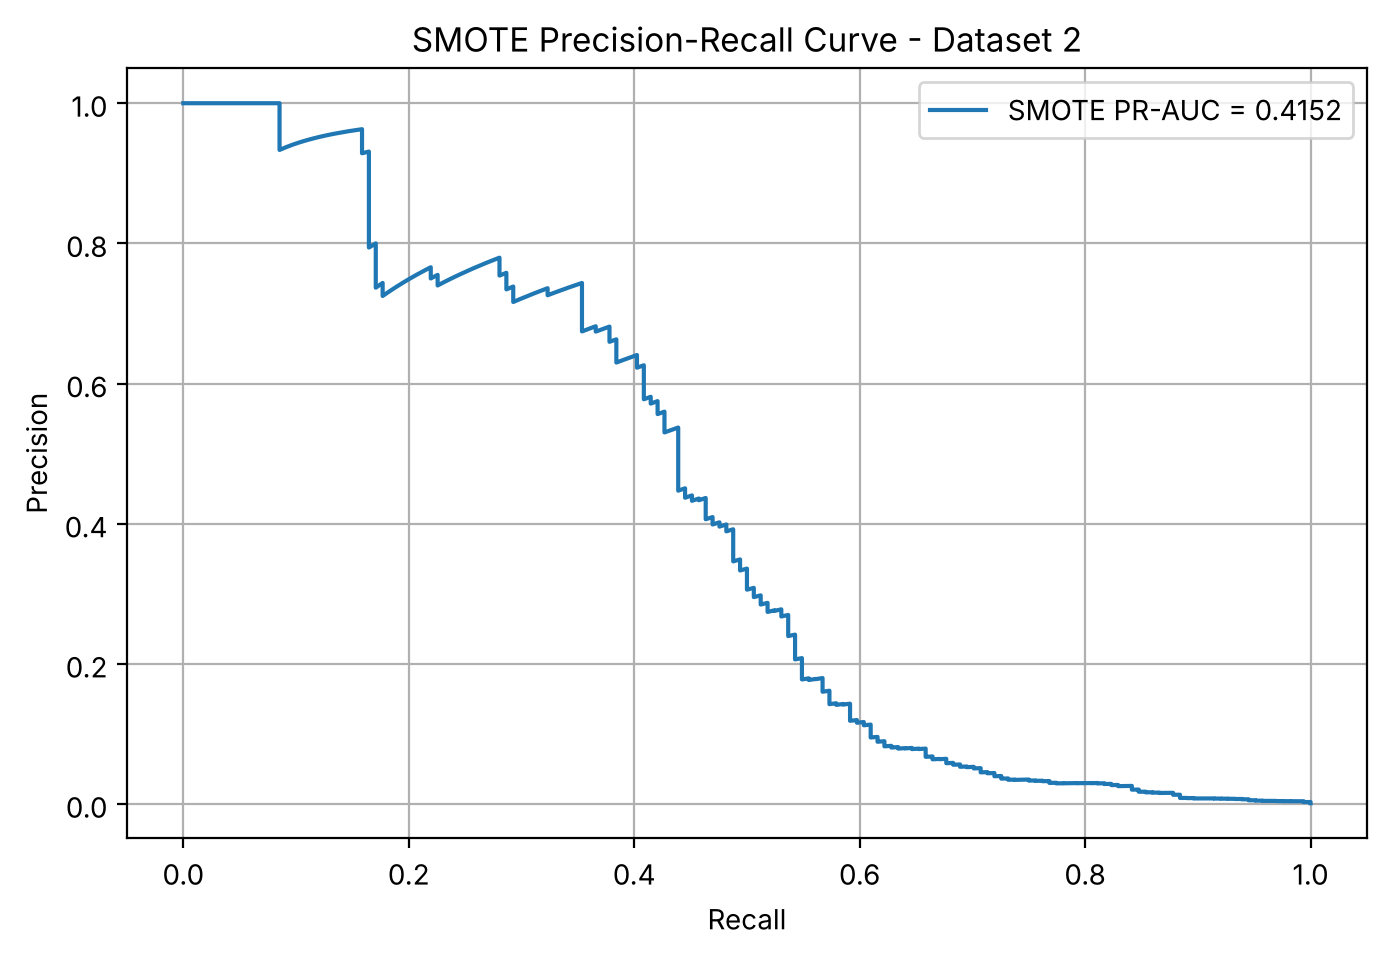

In [51]:
precision_smote2, recall_smote2, thresholds_smote2 = (
    precision_recall_curve(
        y2_test,
        y2_smote_scores
    )
)

plt.figure(figsize=(8, 5))

plt.plot(
    recall_smote2,
    precision_smote2,
    label=f"SMOTE PR-AUC = {smote_pr_auc2:.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("SMOTE Precision-Recall Curve - Dataset 2")

plt.legend()
plt.grid(True)

plt.show()

### Economic Cost

In [52]:
COST_FN = 5000
COST_FP = 100

def calculate_economic_cost(y_true, y_pred):

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    total_cost = (
        COST_FN * fn +
        COST_FP * fp
    )

    return {
        "False Negatives": int(fn),
        "False Positives": int(fp),
        "True Positives": int(tp),
        "True Negatives": int(tn),
        "Total Economic Cost (INR)": int(total_cost)
    }

In [53]:
baseline_cost2 = calculate_economic_cost(
    y2_test,
    y2_baseline_pred
)

smote_cost2 = calculate_economic_cost(
    y2_test,
    y2_smote_pred
)

print("BASELINE ECONOMIC COST:")
print(baseline_cost2)

print("\nSMOTE ECONOMIC COST:")
print(smote_cost2)

BASELINE ECONOMIC COST:
{'False Negatives': 151, 'False Positives': 0, 'True Positives': 13, 'True Negatives': 127089, 'Total Economic Cost (INR)': 755000}

SMOTE ECONOMIC COST:
{'False Negatives': 67, 'False Positives': 610, 'True Positives': 97, 'True Negatives': 126479, 'Total Economic Cost (INR)': 396000}


In [54]:
results_dataset2 = pd.DataFrame([
    {
        "Dataset": "PaySim",
        "Method": "Baseline",
        "PR-AUC": baseline_pr_auc2,
        "Precision": baseline_precision2,
        "Recall": baseline_recall2,
        **baseline_cost2
    },
    {
        "Dataset": "PaySim",
        "Method": "SMOTE",
        "PR-AUC": smote_pr_auc2,
        "Precision": smote_precision2,
        "Recall": smote_recall2,
        **smote_cost2
    }
])

display(results_dataset2.round(4))

,Dataset,Method,PR-AUC,Precision,Recall,False Negatives,False Positives,True Positives,True Negatives,Total Economic Cost (INR)
0,PaySim,Baseline,0.2093,1.0000,0.0793,151,0,13,127089,755000
1,PaySim,SMOTE,0.4152,0.1372,0.5915,67,610,97,126479,396000


<Figure size 1800x1000 with 0 Axes>

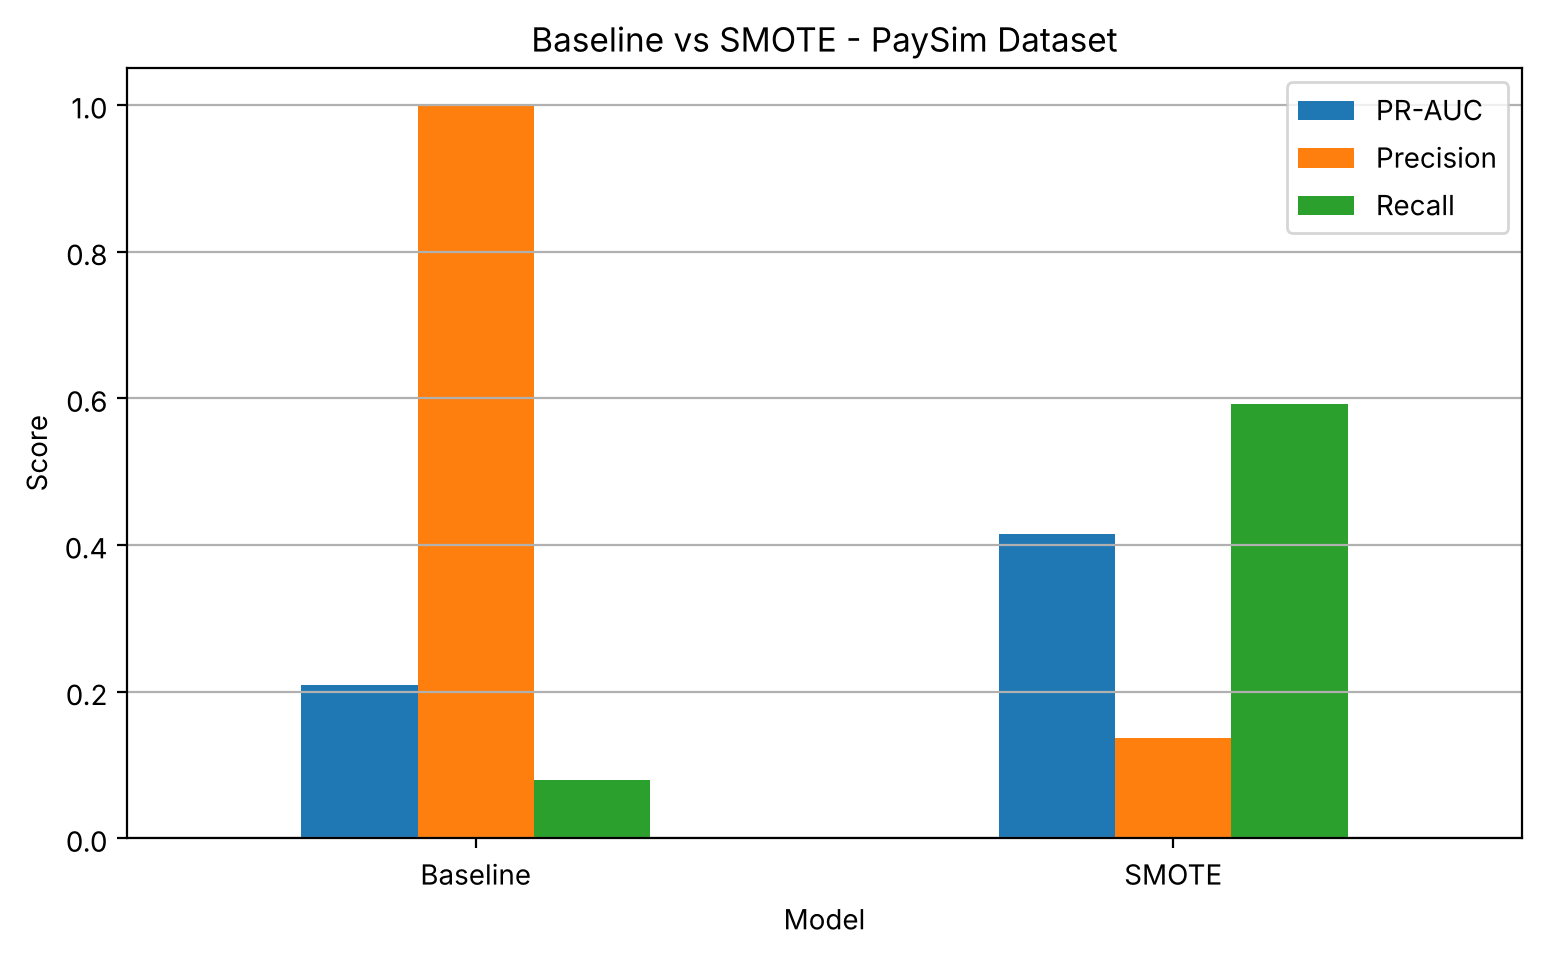

In [55]:
plt.figure(figsize=(9, 5))

results_dataset2.set_index("Method")[
    ["PR-AUC", "Precision", "Recall"]
].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Baseline vs SMOTE - PaySim Dataset")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.grid(axis="y")

plt.show()

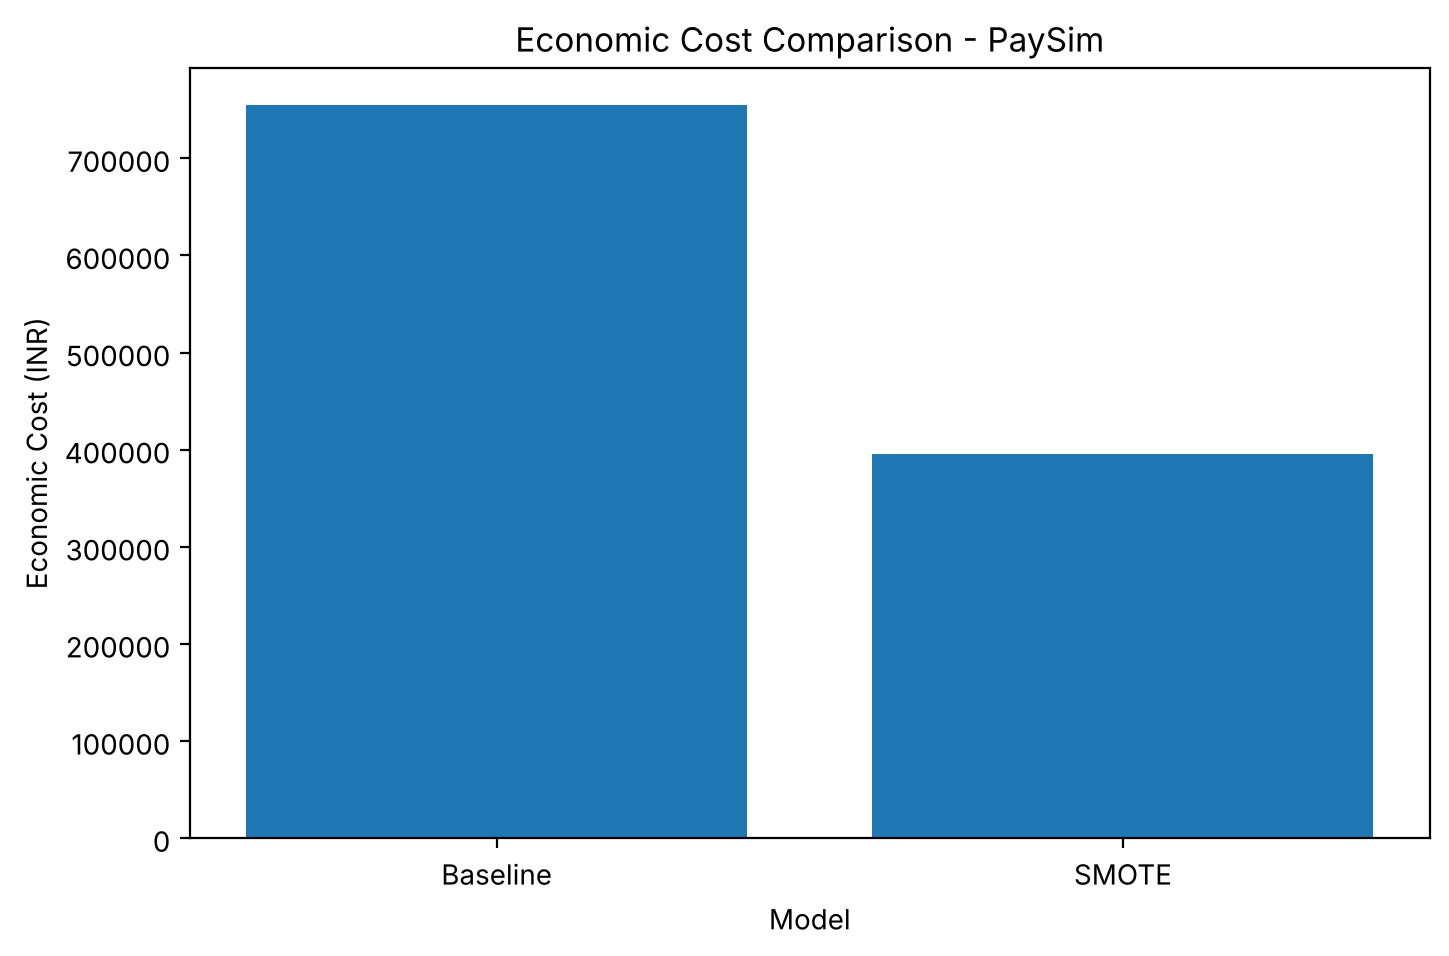

In [56]:
plt.figure(figsize=(8, 5))

cost_values = [
    baseline_cost2["Total Economic Cost (INR)"],
    smote_cost2["Total Economic Cost (INR)"]
]

plt.bar(
    ["Baseline", "SMOTE"],
    cost_values
)

plt.title("Economic Cost Comparison - PaySim")
plt.ylabel("Economic Cost (INR)")
plt.xlabel("Model")

plt.show()

In [57]:
pr_auc_change2 = (
    (smote_pr_auc2 - baseline_pr_auc2)
    / baseline_pr_auc2 * 100
    if baseline_pr_auc2 != 0 else np.nan
)

baseline_total_cost2 = baseline_cost2["Total Economic Cost (INR)"]
smote_total_cost2 = smote_cost2["Total Economic Cost (INR)"]

cost_change2 = (
    (smote_total_cost2 - baseline_total_cost2)
    / baseline_total_cost2 * 100
    if baseline_total_cost2 != 0 else np.nan
)

print("PERFORMANCE COMPARISON")
print("--------------------------------")

print(f"PR-AUC Change: {pr_auc_change2:.2f}%")
print(f"Economic Cost Change: {cost_change2:.2f}%")

if smote_total_cost2 < baseline_total_cost2:
    print("SMOTE has lower economic cost.")

elif smote_total_cost2 > baseline_total_cost2:
    print("Baseline has lower economic cost.")

else:
    print("Both methods have equal economic cost.")

PERFORMANCE COMPARISON
--------------------------------
PR-AUC Change: 98.40%
Economic Cost Change: -47.55%
SMOTE has lower economic cost.


In [58]:
results_dataset2.to_csv(
    "PaySim_Results.csv",
    index=False
)

print("Results saved successfully!")

Results saved successfully!


## 3. Combined Results

In [59]:

# Load both result files
results_dataset1 = pd.read_csv("Credit_Card_Fraud_Results.csv")
results_dataset2 = pd.read_csv("PaySim_Results.csv")

# Standardize Dataset 1 columns
results_dataset1 = results_dataset1.rename(columns={
    "Model": "Method",
    "Economic Cost (₹)": "Total Economic Cost (INR)"
})

results_dataset1["Dataset"] = "Credit Card Fraud"

# Standardize Dataset 2 columns
results_dataset2["Dataset"] = "PaySim"

# Keep the same columns in both datasets
common_columns = [
    "Dataset",
    "Method",
    "PR-AUC",
    "Precision",
    "Recall",
    "False Positives",
    "False Negatives",
    "Total Economic Cost (INR)"
]

results_dataset1 = results_dataset1[common_columns]
results_dataset2 = results_dataset2[common_columns]

# Combine both datasets
final_results = pd.concat(
    [results_dataset1, results_dataset2],
    ignore_index=True
)

# Display final comparison
display(final_results.round(4))

# Export final CSV
final_results.to_csv(
    "Group6_Final_Comparison.csv",
    index=False
)

print("Final comparison file created successfully!")

,Dataset,Method,PR-AUC,Precision,Recall,False Positives,False Negatives,Total Economic Cost (INR)
0,Credit Card Fraud,Baseline Logistic Regression,0.7414,0.8267,0.6327,13,36,181300
1,Credit Card Fraud,Logistic Regression + SMOTE,0.7505,0.3522,0.8878,160,11,71000
2,PaySim,Baseline,0.2093,1.0000,0.0793,0,151,755000
3,PaySim,SMOTE,0.4152,0.1372,0.5915,610,67,396000


Final comparison file created successfully!


## 4. Cost-Sensitive Methods
Same split and seed as above.
- class_weight = 'balanced'
- class_weight = {0: 1, 1: 50} (cost ratio 5000 / 100)
- threshold moving: baseline model with threshold = 100 / (100 + 5000) ≈ 0.0196

In [60]:
from sklearn.base import clone
from sklearn.metrics import f1_score

C_FN = 5000
C_FP = 100
COST_RATIO = C_FN / C_FP
BAYES_THRESHOLD = C_FP / (C_FP + C_FN)


def evaluate(dataset, method, y_true, scores, threshold=0.5):
    y_pred = (scores > threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "Dataset": dataset,
        "Method": method,
        "Threshold": round(threshold, 4),
        "PR-AUC": average_precision_score(y_true, scores),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "False Positives": int(fp),
        "False Negatives": int(fn),
        "Total Economic Cost (INR)": int(C_FN * fn + C_FP * fp),
    }


print("Threshold for threshold moving:", round(BAYES_THRESHOLD, 4))

Threshold for threshold moving: 0.0196


### Credit Card Fraud

In [61]:
cs_bal_model1 = LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced")
cs_bal_model1.fit(X1_train_scaled, y1_train)

cs_ratio_model1 = LogisticRegression(max_iter=1000, random_state=42, class_weight={0: 1, 1: COST_RATIO})
cs_ratio_model1.fit(X1_train_scaled, y1_train)

cs_bal_prob1 = cs_bal_model1.predict_proba(X1_test_scaled)[:, 1]
cs_ratio_prob1 = cs_ratio_model1.predict_proba(X1_test_scaled)[:, 1]

results_cs1 = pd.DataFrame([
    evaluate("Credit Card Fraud", "Baseline LR", y1_test, baseline_prob1),
    evaluate("Credit Card Fraud", "SMOTE (resampling)", y1_test, smote_prob1),
    evaluate("Credit Card Fraud", "CS: class_weight=balanced", y1_test, cs_bal_prob1),
    evaluate("Credit Card Fraud", "CS: class_weight=cost ratio (1:50)", y1_test, cs_ratio_prob1),
    evaluate("Credit Card Fraud", "CS: threshold moving (Bayes)", y1_test, baseline_prob1, threshold=BAYES_THRESHOLD),
])

display(results_cs1.round(4))

,Dataset,Method,Threshold,PR-AUC,Precision,Recall,F1,False Positives,False Negatives,Total Economic Cost (INR)
0,Credit Card Fraud,Baseline LR,0.5000,0.7414,0.8267,0.6327,0.7168,13,36,181300
1,Credit Card Fraud,SMOTE (resampling),0.5000,0.7505,0.3522,0.8878,0.5043,160,11,71000
2,Credit Card Fraud,CS: class_weight=balanced,0.5000,0.7190,0.0610,0.9184,0.1144,1386,8,178600
3,Credit Card Fraud,CS: class_weight=cost ratio (1:50),0.5000,0.7479,0.4485,0.8878,0.5959,107,11,65700
4,Credit Card Fraud,CS: threshold moving (Bayes),0.0196,0.7414,0.5337,0.8878,0.6667,76,11,62600


### PaySim

In [62]:
cs_bal_model2 = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced"))
])
cs_bal_model2.fit(X2_train, y2_train)

cs_ratio_model2 = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", LogisticRegression(max_iter=1000, random_state=42, class_weight={0: 1, 1: COST_RATIO}))
])
cs_ratio_model2.fit(X2_train, y2_train)

cs_bal_scores2 = cs_bal_model2.predict_proba(X2_test)[:, 1]
cs_ratio_scores2 = cs_ratio_model2.predict_proba(X2_test)[:, 1]

results_cs2 = pd.DataFrame([
    evaluate("PaySim", "Baseline LR", y2_test, y2_baseline_scores),
    evaluate("PaySim", "SMOTE (resampling)", y2_test, y2_smote_scores),
    evaluate("PaySim", "SMOTENC (resampling)", y2_test, y2_smotenc_scores),
    evaluate("PaySim", "CS: class_weight=balanced", y2_test, cs_bal_scores2),
    evaluate("PaySim", "CS: class_weight=cost ratio (1:50)", y2_test, cs_ratio_scores2),
    evaluate("PaySim", "CS: threshold moving (Bayes)", y2_test, y2_baseline_scores, threshold=BAYES_THRESHOLD),
])

display(results_cs2.round(4))

,Dataset,Method,Threshold,PR-AUC,Precision,Recall,F1,False Positives,False Negatives,Total Economic Cost (INR)
0,PaySim,Baseline LR,0.5000,0.2093,1.0000,0.0793,0.1469,0,151,755000
1,PaySim,SMOTE (resampling),0.5000,0.4152,0.1372,0.5915,0.2227,610,67,396000
2,PaySim,SMOTENC (resampling),0.5000,0.4148,0.1366,0.5915,0.2220,613,67,396300
3,PaySim,CS: class_weight=balanced,0.5000,0.2663,0.0147,0.9146,0.0289,10077,14,1077700
4,PaySim,CS: class_weight=cost ratio (1:50),0.5000,0.4303,0.2378,0.5366,0.3296,282,76,408200
5,PaySim,CS: threshold moving (Bayes),0.0196,0.2093,0.1017,0.4756,0.1676,689,86,498900


### Final Comparison

In [63]:
final_results_v2 = pd.concat([results_cs1, results_cs2], ignore_index=True)
display(final_results_v2.round(4))

final_results_v2.to_csv("Group6_Final_Comparison_v2.csv", index=False)
print("Saved Group6_Final_Comparison_v2.csv")

,Dataset,Method,Threshold,PR-AUC,Precision,Recall,F1,False Positives,False Negatives,Total Economic Cost (INR)
0,Credit Card Fraud,Baseline LR,0.5000,0.7414,0.8267,0.6327,0.7168,13,36,181300
1,Credit Card Fraud,SMOTE (resampling),0.5000,0.7505,0.3522,0.8878,0.5043,160,11,71000
2,Credit Card Fraud,CS: class_weight=balanced,0.5000,0.7190,0.0610,0.9184,0.1144,1386,8,178600
3,Credit Card Fraud,CS: class_weight=cost ratio (1:50),0.5000,0.7479,0.4485,0.8878,0.5959,107,11,65700
4,Credit Card Fraud,CS: threshold moving (Bayes),0.0196,0.7414,0.5337,0.8878,0.6667,76,11,62600
5,PaySim,Baseline LR,0.5000,0.2093,1.0000,0.0793,0.1469,0,151,755000
6,PaySim,SMOTE (resampling),0.5000,0.4152,0.1372,0.5915,0.2227,610,67,396000
7,PaySim,SMOTENC (resampling),0.5000,0.4148,0.1366,0.5915,0.2220,613,67,396300
8,PaySim,CS: class_weight=balanced,0.5000,0.2663,0.0147,0.9146,0.0289,10077,14,1077700
9,PaySim,CS: class_weight=cost ratio (1:50),0.5000,0.4303,0.2378,0.5366,0.3296,282,76,408200


Saved Group6_Final_Comparison_v2.csv


## 5. Results over 3 Random Seeds

In [64]:
SEEDS = [42, 7, 2024]


def run_all_methods(X, y, make_preprocessor, dataset_name, seed):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.20, random_state=seed, stratify=y)

    models = {
        "Baseline LR": Pipeline([
            ("prep", make_preprocessor()),
            ("model", LogisticRegression(max_iter=1000, random_state=seed))]),
        "SMOTE (resampling)": Pipeline([
            ("prep", make_preprocessor()),
            ("smote", SMOTE(sampling_strategy=0.1, random_state=seed, k_neighbors=5)),
            ("model", LogisticRegression(max_iter=1000, random_state=seed))]),
        "CS: class_weight=balanced": Pipeline([
            ("prep", make_preprocessor()),
            ("model", LogisticRegression(max_iter=1000, random_state=seed, class_weight="balanced"))]),
        "CS: class_weight=cost ratio (1:50)": Pipeline([
            ("prep", make_preprocessor()),
            ("model", LogisticRegression(max_iter=1000, random_state=seed, class_weight={0: 1, 1: COST_RATIO}))]),
    }

    rows = []
    for name, model in models.items():
        model.fit(X_tr, y_tr)
        scores = model.predict_proba(X_te)[:, 1]
        result = evaluate(dataset_name, name, y_te, scores)
        result["Seed"] = seed
        rows.append(result)
        if name == "Baseline LR":
            result = evaluate(dataset_name, "CS: threshold moving (Bayes)", y_te, scores, threshold=BAYES_THRESHOLD)
            result["Seed"] = seed
            rows.append(result)
    return rows


all_rows = []
for seed in SEEDS:
    all_rows += run_all_methods(X1, y1, StandardScaler, "Credit Card Fraud", seed)
    all_rows += run_all_methods(X2, y2, lambda: clone(preprocessor), "PaySim", seed)
    print("Seed", seed, "done")

multi_seed = pd.DataFrame(all_rows)
multi_seed.to_csv("Group6_MultiSeed_Results.csv", index=False)

summary = (multi_seed
           .groupby(["Dataset", "Method"])[["PR-AUC", "Precision", "Recall", "Total Economic Cost (INR)"]]
           .agg(["mean", "std"])
           .round(4))
summary.to_csv("Group6_MultiSeed_Summary.csv")
display(summary)

Seed 42 done


Seed 7 done


Seed 2024 done


PR-AUC          \
                                                        mean     std   
Dataset           Method                                               
Credit Card Fraud Baseline LR                         0.7505  0.0295   
                  CS: class_weight=balanced           0.7268  0.0223   
                  CS: class_weight=cost ratio (1:50)  0.7506  0.0246   
                  CS: threshold moving (Bayes)        0.7505  0.0295   
                  SMOTE (resampling)                  0.7483  0.0233   
PaySim            Baseline LR                         0.1732  0.0430   
                  CS: class_weight=balanced           0.2146  0.0448   
                  CS: class_weight=cost ratio (1:50)  0.3656  0.0566   
                  CS: threshold moving (Bayes)        0.1732  0.0430   
                  SMOTE (resampling)                  0.3465  0.0596   

                                                     Precision          \
                                                          mean     std   
Dataset           Method                                                 
Credit Card Fraud Baseline LR                           0.8602  0.0423   
                  CS: class_weight=balanced             0.0646  0.0032   
                  CS: class_weight=cost ratio (1:50)    0.4954  0.0407   
                  CS: threshold moving (Bayes)          0.5769  0.0406   
                  SMOTE (resampling)                    0.3770  0.0216   
PaySim            Baseline LR                           0.9556  0.0770   
                  CS: class_weight=balanced             0.0148  0.0001   
                  CS: class_weight=cost ratio (1:50)    0.2283  0.0115   
                  CS: threshold moving (Bayes)          0.0975  0.0063   
                  SMOTE (resampling)                    0.1286  0.0090   

                                                      Recall          \
                                                        mean     std   
Dataset           Method                                               
Credit Card Fraud Baseline LR                         0.5986  0.0358   
                  CS: class_weight=balanced           0.9116  0.0212   
                  CS: class_weight=cost ratio (1:50)  0.8571  0.0306   
                  CS: threshold moving (Bayes)        0.8639  0.0328   
                  SMOTE (resampling)                  0.8639  0.0257   
PaySim            Baseline LR                         0.0650  0.0246   
                  CS: class_weight=balanced           0.9024  0.0122   
                  CS: class_weight=cost ratio (1:50)  0.5041  0.0307   
                  CS: threshold moving (Bayes)        0.4065  0.0602   
                  SMOTE (resampling)                  0.5671  0.0220   

                                                     Total Economic Cost (INR)  \
                                                                          mean   
Dataset           Method                                                         
Credit Card Fraud Baseline LR                                     1.976333e+05   
                  CS: class_weight=balanced                       1.730333e+05   
                  CS: class_weight=cost ratio (1:50)              7.866667e+04   
                  CS: threshold moving (Bayes)                    7.293333e+04   
                  SMOTE (resampling)                              8.073333e+04   
PaySim            Baseline LR                                     7.667333e+05   
                  CS: class_weight=balanced                       1.064300e+06   
                  CS: class_weight=cost ratio (1:50)              4.346000e+05   
                  CS: threshold moving (Bayes)                    5.483333e+05   
                  SMOTE (resampling)                              4.181667e+05   

                                                                  
                                                             std  
Dataset         

In [65]:
# lowest cost method for each seed
best = multi_seed.loc[multi_seed.groupby(["Dataset", "Seed"])["Total Economic Cost (INR)"].idxmin(),
                      ["Dataset", "Seed", "Method", "Total Economic Cost (INR)"]]
display(best)

,Dataset,Seed,Method,Total Economic Cost (INR)
11,Credit Card Fraud,7,CS: threshold moving (Bayes),65400
1,Credit Card Fraud,42,CS: threshold moving (Bayes),62600
21,Credit Card Fraud,2024,CS: threshold moving (Bayes),90800
17,PaySim,7,SMOTE (resampling),428000
7,PaySim,42,SMOTE (resampling),396000
27,PaySim,2024,SMOTE (resampling),430500


## 6. Plots

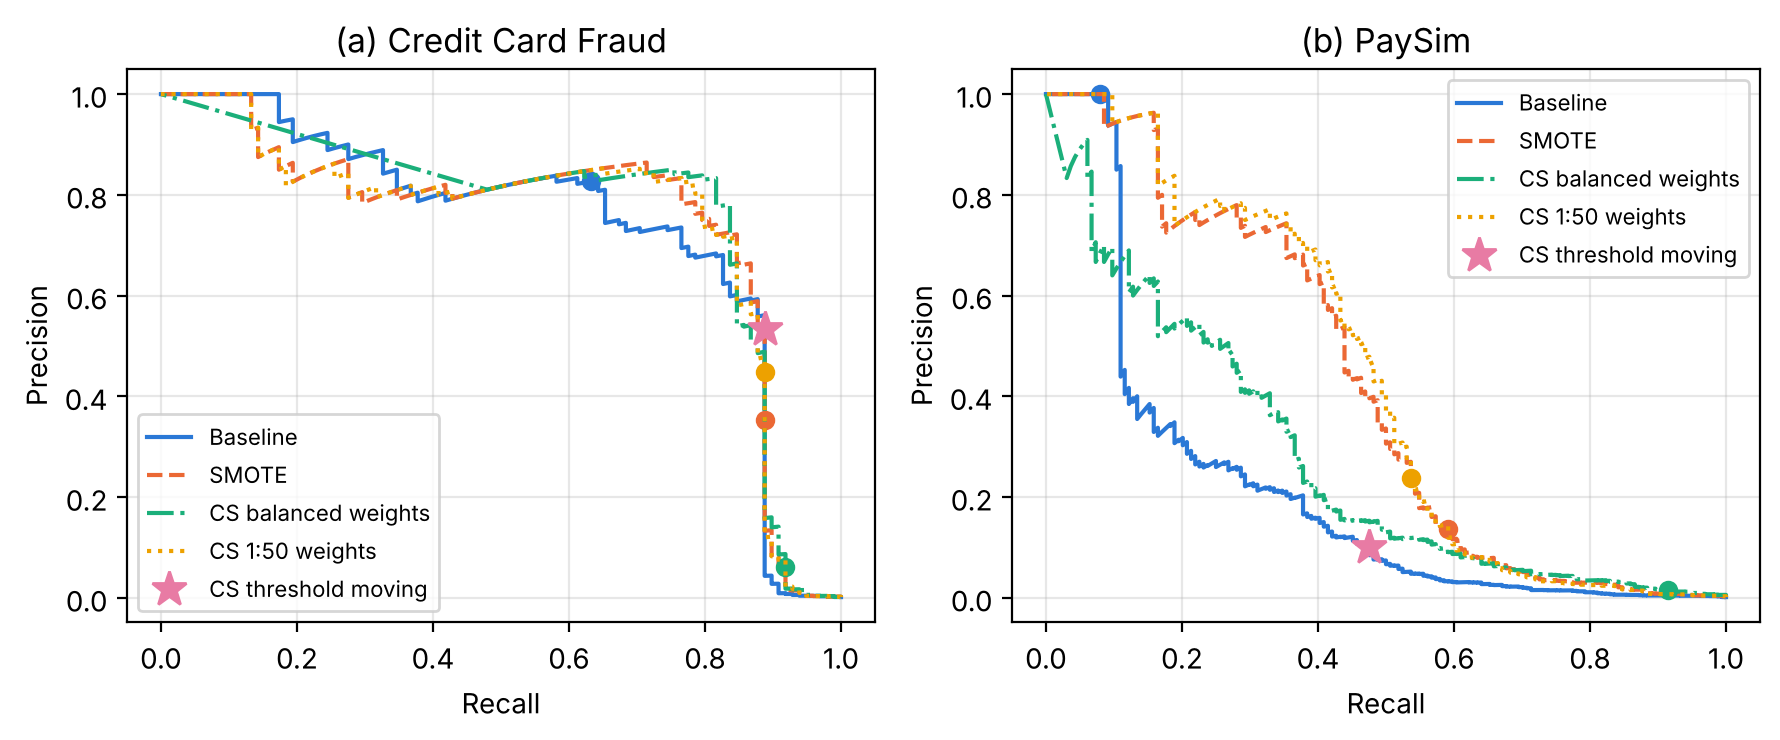

In [66]:
methods = ["Baseline LR", "SMOTE (resampling)", "CS: class_weight=balanced",
           "CS: class_weight=cost ratio (1:50)", "CS: threshold moving (Bayes)"]
names = ["Baseline", "SMOTE", "CS balanced weights", "CS 1:50 weights", "CS threshold moving"]
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
styles = ["-", "--", "-.", ":", "-"]

scores1 = [baseline_prob1, smote_prob1, cs_bal_prob1, cs_ratio_prob1]
scores2 = [y2_baseline_scores, y2_smote_scores, cs_bal_scores2, cs_ratio_scores2]

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
plots = [(axes[0], y1_test, scores1, "(a) Credit Card Fraud", "lower left"),
         (axes[1], y2_test, scores2, "(b) PaySim", "upper right")]

for ax, y_true, scores, title, legend_pos in plots:
    for i in range(4):
        p, r, _ = precision_recall_curve(y_true, scores[i])
        ax.plot(r, p, color=colors[i], linestyle=styles[i], label=names[i])
        pred = (scores[i] > 0.5).astype(int)
        ax.plot(recall_score(y_true, pred), precision_score(y_true, pred, zero_division=0), "o", color=colors[i])
    # threshold moving = baseline model with the lower threshold
    pred = (scores[0] > BAYES_THRESHOLD).astype(int)
    ax.plot(recall_score(y_true, pred), precision_score(y_true, pred), "*", markersize=13,
            color=colors[4], label=names[4])
    ax.set_title(title)
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc=legend_pos)

plt.tight_layout()
plt.savefig("pr_curves.png", dpi=250)
plt.show()

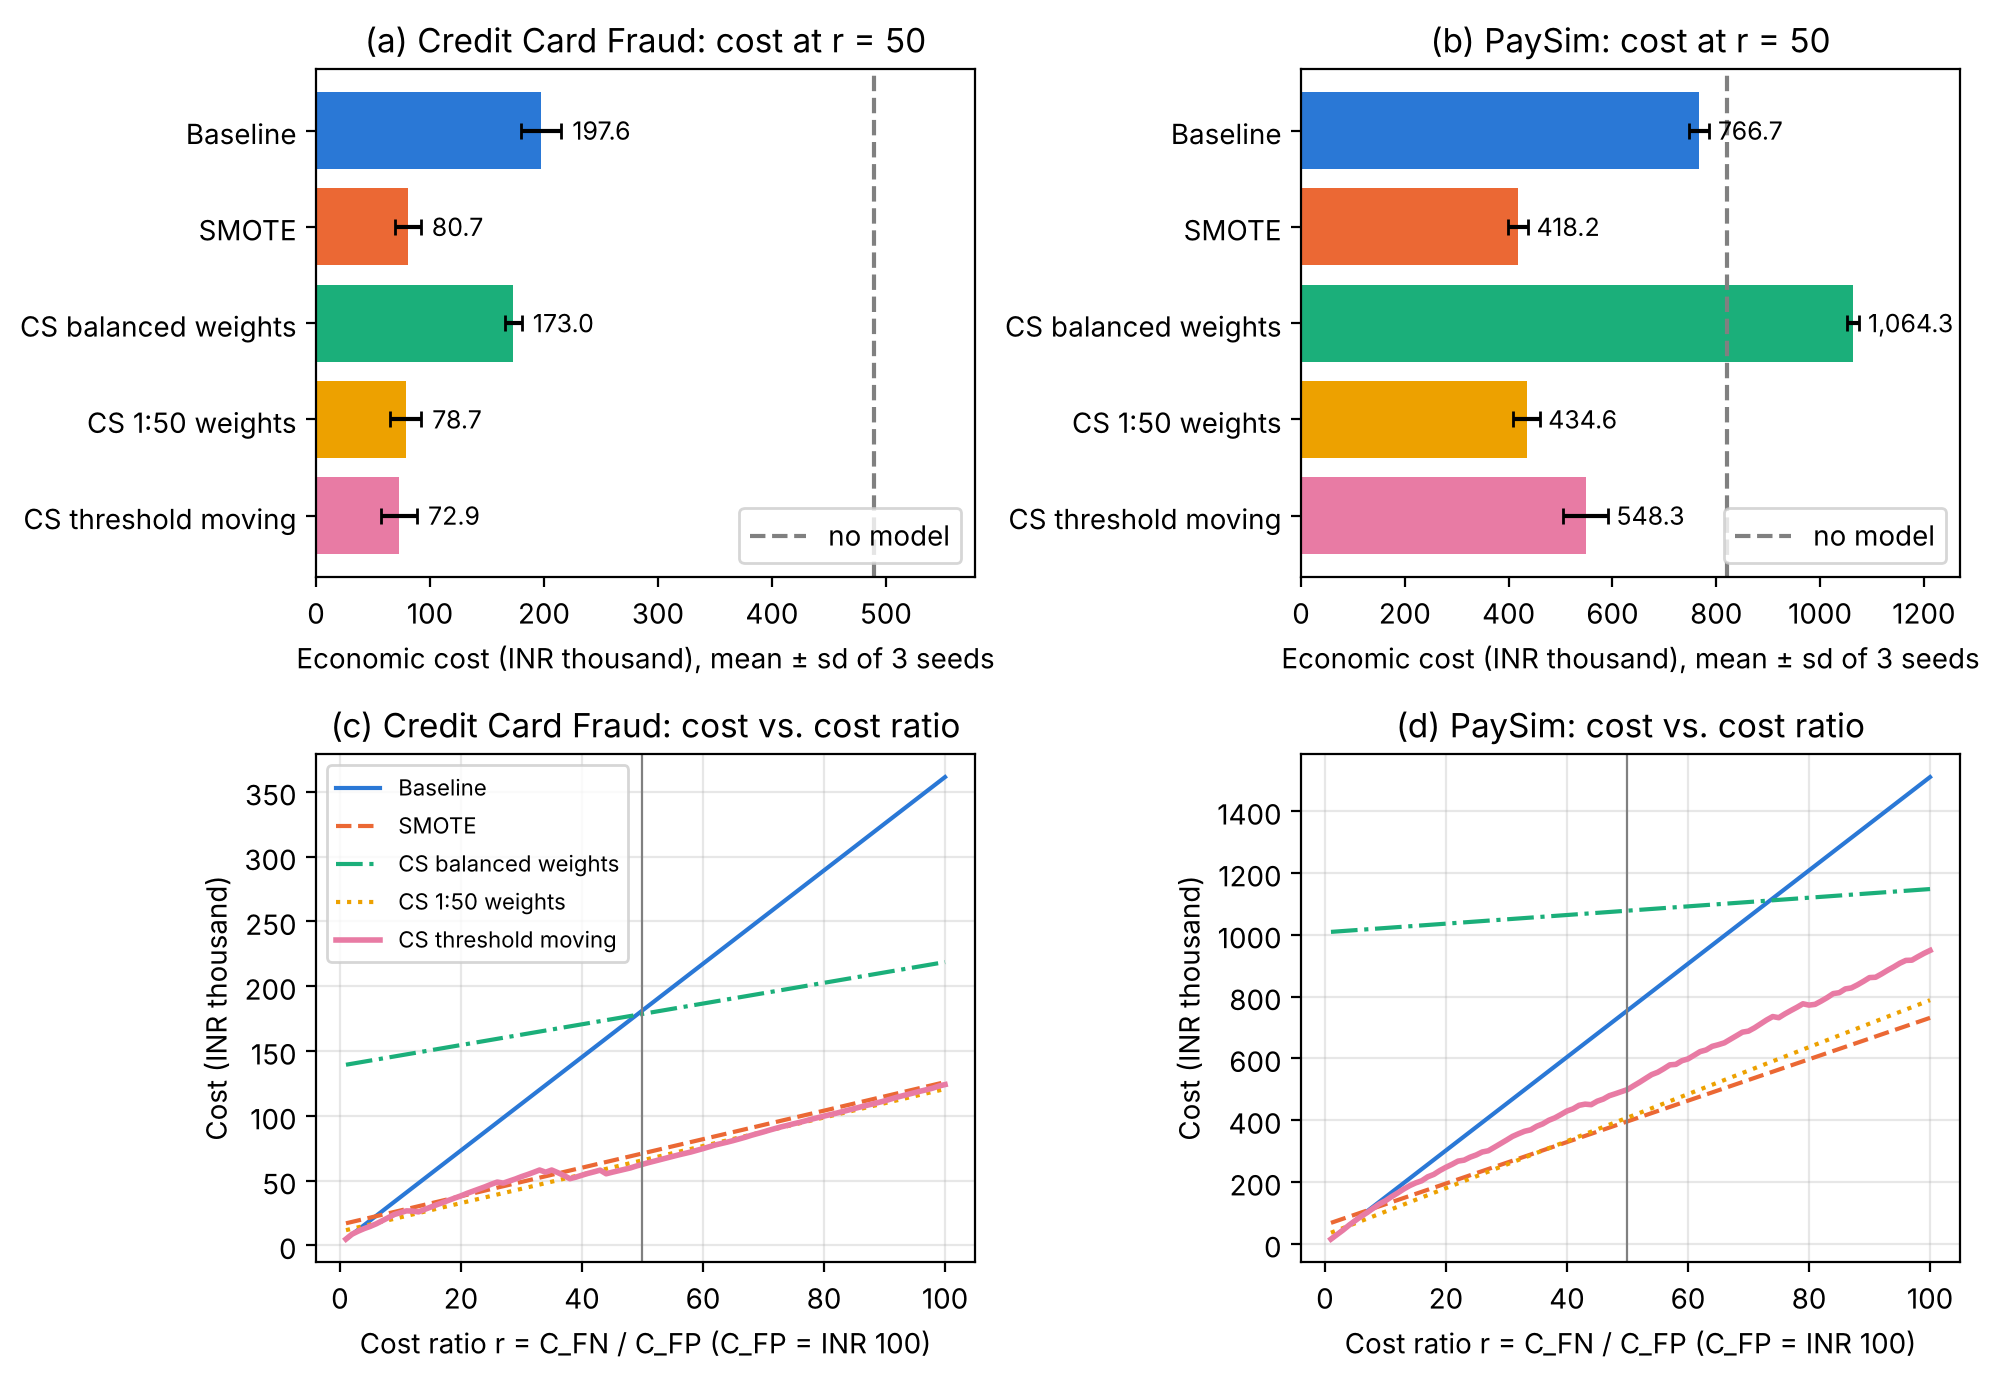

In [67]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

# top row: mean cost over the 3 seeds
for ax, dataset, y_true, title in [(axes[0, 0], "Credit Card Fraud", y1_test, "(a) Credit Card Fraud: cost at r = 50"),
                                   (axes[0, 1], "PaySim", y2_test, "(b) PaySim: cost at r = 50")]:
    res = (multi_seed[multi_seed["Dataset"] == dataset]
           .groupby("Method")["Total Economic Cost (INR)"].agg(["mean", "std"])
           .reindex(methods) / 1000)
    no_model = y_true.sum() * C_FN / 1000
    ax.barh(names, res["mean"], xerr=res["std"], color=colors, capsize=3)
    ax.invert_yaxis()
    ax.axvline(no_model, color="gray", linestyle="--", label="no model")
    for i, (m, s) in enumerate(zip(res["mean"], res["std"])):
        ax.text(m + s + no_model * 0.02, i, f"{m:,.1f}", va="center", fontsize=9)
    ax.set_xlim(0, max(no_model, (res["mean"] + res["std"]).max()) * 1.18)
    ax.set_xlabel("Economic cost (INR thousand), mean ± sd of 3 seeds")
    ax.set_title(title)
    ax.legend(loc="lower right")

# bottom row: cost when the cost ratio r changes (seed 42)
r_values = np.arange(1, 101)
for ax, y_true, scores, title in [(axes[1, 0], y1_test, scores1, "(c) Credit Card Fraud: cost vs. cost ratio"),
                                  (axes[1, 1], y2_test, scores2, "(d) PaySim: cost vs. cost ratio")]:
    for i in range(4):
        tn, fp, fn, tp = confusion_matrix(y_true, (scores[i] > 0.5).astype(int)).ravel()
        ax.plot(r_values, C_FP * (fp + r_values * fn) / 1000, color=colors[i], linestyle=styles[i], label=names[i])
    tm_cost = []
    for r in r_values:
        tn, fp, fn, tp = confusion_matrix(y_true, (scores[0] > 1 / (1 + r)).astype(int)).ravel()
        tm_cost.append(C_FP * (fp + r * fn) / 1000)
    ax.plot(r_values, tm_cost, color=colors[4], linewidth=2, label=names[4])
    ax.axvline(50, color="gray", linewidth=0.8)
    ax.set_xlabel("Cost ratio r = C_FN / C_FP (C_FP = INR 100)")
    ax.set_ylabel("Cost (INR thousand)")
    ax.set_title(title)
    ax.grid(alpha=0.3)
axes[1, 0].legend(fontsize=8, loc="upper left")

plt.tight_layout()
plt.savefig("costs.png", dpi=250)
plt.show()

## 7. Library Versions

In [68]:
import sys, sklearn, imblearn, matplotlib

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("imbalanced-learn:", imblearn.__version__)
print("matplotlib:", matplotlib.__version__)
print("seaborn:", sns.__version__)

Python: 3.13.18
pandas: 3.0.5
numpy: 2.5.3
scikit-learn: 1.9.1
imbalanced-learn: 0.14.2
matplotlib: 3.11.2
seaborn: 0.13.2
